# Neural dynamics: flow fields and attractors

Do the **network dynamics** that generate the neural trajectories change across learning and
remapping — not just the trajectories themselves? We estimate, from the population activity, the
**velocity vector field** (flow field) of a low-dimensional latent state, then read off its
**fixed points, attractors, basins and slow manifolds**, and ask how those change:

1. across **learning days** in the stable-control phase, and between **correct / incorrect /
   baseline**;
2. across the **remapping days**, each on its own — the first ~10 min of intuitive control
   *before* the rotation, the new-axis block *after* it, and the intuitive-axis **washout**.

Method after **Luo, Kim et al. (2025), *Nature* 646:1156** and its FINDR engine
(Kim et al., ICML 2025). Reusable tools live in `utilities/dynamics_utils.py` (imported as `dy`),
with data access and condition definitions from `utilities/neural_analysis_utils.py` (`na`).
All analysis flow and plotting stay open in this notebook.

---

## Methods

### 1. What is estimated

A latent state `z` of dimension `d` evolving as a stochastic differential equation, discretised at
the analysis time step `dt`:

$$z_{t+1} = z_t + \Delta t\, F(z_t) + \sqrt{\Delta t}\,\sigma_z\,\epsilon_t$$

**`F` is the object of interest** — the flow field. It is parameterised as a **gated neural ODE**
(Kim, Can & Krishnamurthy 2023, the parameterisation FINDR uses):

$$F(z) = G(z) \odot \big[-z + f(z)\big] / \tau$$

with `G` a sigmoid-output network, so the *effective* time constant `τ/G` is state dependent. That
gating is what lets one field carry both fast and very slow directions, i.e. express approximate
line / continuous attractors rather than only isolated points.

Each neuron's activity is read out linearly, through a softplus, with Gaussian noise:

$$y_{t,n} \sim \mathcal{N}\!\big(\mathrm{softplus}(w_n \cdot z_t + b_{t,n} + c_n),\ s_n^2\big)$$

A bidirectional GRU infers the latent path from the whole segment; the loss is FINDR's
reconstruction term plus `c_dyn` × the Euler/Girsanov term that forces `F` to match the inferred
dynamics.

### 2. Preprocessing, and why

| choice | value | reason (measured on this data) |
|---|---|---|
| bin size | 5 frames (30 → **6 Hz**, `dt` = 167 ms) | cross-validated predictability of `dz` from `z` peaks here: 0.12–0.15 at 33 ms → 0.15–0.31 at 167 ms, while the white-noise share of the latents falls 0.19 → 0.10–0.16 |
| transform | **`sqrt`** | raw activity has skew 4.2 / kurtosis 30 and a var-vs-mean slope of 1.5; after `sqrt`, 1.5 / 4.9 / 0.92 |
| noise model | **Gaussian**, per-neuron variance | per-neuron var/mean is 63–98 (Poisson would be 1) and the values are continuous, not counts |
| per-neuron scale | robust, computed on **baseline** timepoints | removes cross-day gain differences without letting a condition contrast rescale itself away |
| nuisance | slow drift only, ~15 min basis functions | see below |

### 3. The nuisance model is deliberately minimal

Only **session-scale drift** (bleaching, z-drift, arousal) is removed. Everything else is treated as
a *control variable*, not a regressor:

* **Licking** is time-locked to reward and **locomotion** is coupled to task engagement, so
  regressing them out risks deleting signal. **Trial-onset kernels** would absorb exactly the
  average trial-locked trajectory the flow field is meant to describe.
* **Brain-motion / z-drift metrics** (`motionCorrection`) are *not* regressed out: these traces are
  already registered, and the shifts are driven by locomotion, so removing them could remove real
  signal. They are instead checked for systematic differences across the partitions being compared.
* Drift bases are kept to ~15 min each **on purpose**. High-passing at ~60 s does raise the apparent
  predictability of `dz` from `z` (0.21 → 0.41), but slow neural dynamics live at that timescale — a
  line attractor produces exactly that kind of slow wandering — so removing it would delete the
  phenomenon we are looking for.

### 4. What is identifiable, and what is not

* **No input term.** In FINDR, `u` is the exogenous click train. Here the auditory tone is a *readout*
  of the population state, so feeding it in as an input would relabel autonomous dynamics as
  "input dynamics". The field is therefore autonomous, `F(z)`. Genuinely exogenous events (trial
  onset, reward) can be added as `u` — that is identifiable — and the tone can be tested through the
  component of it that is *not* predictable from `z`. Baseline epochs have no tone at all, so
  correct/incorrect vs baseline is already a closed-loop vs free-running contrast.
* **The latent frame is arbitrary** up to an invertible linear map. `dy.canonical_transform` applies
  the paper's fix (SVD of the readout), so distances and angles in the canonical frame are
  meaningful in neural space; a residual rotation/reflection remains, so fields are compared either
  in a *shared* frame or through rotation-invariant summaries.
* **Where the data does not go, the field is extrapolation.** Every statistic here is evaluated at
  the *observed* latent states or inside the sample zone. Validation showed that a direction the
  data explores weakly (`sd_ratio` < ~0.15) is not recoverable **by any method** — so
  `dy.occupancy_anisotropy` is checked before any field is interpreted.
* **`d` is an interpretability choice, not a fitted one.** Held-out loss keeps improving past `d`=5
  with no elbow, so we fit a sweep, report it, and analyse a low `d` whose cost is stated.

### 5. How claims are tested

* **"Do the dynamics differ?"** is a *nested model comparison*: a shared field `F(z)` versus a
  conditioned field `F(z, e)` with a low-dimensional embedding of day / block / condition, judged on
  held-out segments of the same split. This has far more power than fitting one field per partition,
  which the data budget cannot support.
* **Every difference is measured against a noise floor**: the same data refit with a different seed,
  or a split half. Fields are averaged over seeds and the across-seed spread reported, because the
  fit is high-variance at these data volumes (see validation).
* **Attractors are found two independent ways**: local minima of `‖F‖` (each reporting its residual
  speed — a fitted field has no exact zeros), and by integrating the field and clustering where it
  settles. Points outside the data support, or with time constants longer than the session, are
  flagged rather than reported as findings.
* **Trial-length confounds** are handled explicitly: conditions are time-balanced in the loss, miss
  trials are split into a duration-matched head and a late/timeout tail, and occupancy is compared
  as density per unit time.

### 6. Validation (synthetic systems with known fields)

At the realistic noise level, scoring only inside the visited region: point attractor 0.999, line
attractor 0.996, bistable 0.955 (2 stable + 1 saddle, exactly right), DDM line attractor 0.969, two
off-axis attractors 0.992, unstable origin + limit cycle 0.978 (correctly no fixed point). The
**non-normal line attractor fails (0.486)** because its trajectories collapse onto a line — an
identifiability limit, not a bug, and the naive estimator does worse (0.225). Section 1 reproduces
all of this.

---

In [1]:
import sys, os, json, time, math, collections, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import seaborn as sns
from scipy import stats

REPO = Path.cwd(); sys.path.insert(0, str(REPO / "utilities"))
import importlib
import neural_analysis_utils as na; importlib.reload(na)
import dynamics_utils as dy; importlib.reload(dy)
import richfile as rfs; na.register_richfile_types(rfs)
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

# ---------------- CONFIG ----------------
DATA_ROOT = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
MOUSE = "mouse_0403L"          # only remapping animal; 0322R is the outcome-contrast animal
SR = 30.0
# scale_mode="std", NOT "robust": at 30 Hz this signal is 59 % zeros, so MAD-based
# scaling amplifies the noisiest units (white-noise share of the latents 0.745 vs 0.203
# at 33 ms bins). The two agree at the 167 ms bin used here, but the pathology would
# silently corrupt the dt sweep in Fig 7.
PC = dy.PreprocConfig(bin_frames=5, transform="sqrt", scale_mode="std")

D_ANALYSIS = 3                 # latent dims used for field readout (interpretability choice)
D_SWEEP = [2, 3, 4, 5]         # dims compared on held-out loss
SEEDS = [0, 1, 2]              # every field is fit at several seeds; spread = noise floor
EPOCHS = 700
C_DYN = 2.0                    # see section 4; FINDR's 0.1 leaves the field undetermined
C_DYN_SWEEP = [0.1, 2.0, 8.0]  # every headline result is checked across these
MISS_SEC = 20.0                # max trial duration in this dataset
EXAMPLE_DAY_I = 10             # the day used for the walk-through in section 4

RUN_VALIDATION = True          # section 1 (cached; first run ~45 min)
RUN_FITS = True                # sections 4+ (cached per day/variant/seed)
QUICK = False                  # True -> tiny epochs everywhere, for a smoke pass

if QUICK:
    EPOCHS, SEEDS, D_SWEEP = 60, [0], [2, 3]

OUT = REPO / "output" / MOUSE / "dynamics"; OUT.mkdir(parents=True, exist_ok=True)
VAL_OUT = REPO / "output" / "dynamics_validation"; VAL_OUT.mkdir(parents=True, exist_ok=True)
TAG = f"{PC.tag}_d{D_ANALYSIS}_ep{EPOCHS}"

sns.set_context("notebook")
plt.rcParams["figure.dpi"] = 110
dy.enable_fast_matmul()
print(dy.device_report())
print(f"dt = {PC.dt:.4f} s ({PC.sr:.2f} Hz) | preprocessing tag = {PC.tag} | cache tag = {TAG}")

r = na.open_mouse(rfs, DATA_ROOT, MOUSE)
days = na.get_day_list(r)


def day_factors(day):
    t = na.get_true_bmi_trials(na.get_trials_df(r, day))
    f = t.factor[np.isfinite(t.factor)]
    return np.unique(f), len(t)


REMAP_DAYS, STABLE_DAYS = [], []
for d in days:
    f, n = day_factors(d)
    if n == 0:
        continue
    (REMAP_DAYS if f.size > 1 else STABLE_DAYS).append(d)
print(f"{MOUSE}: {len(STABLE_DAYS)} stable days, {len(REMAP_DAYS)} remapping days")

device=cuda:0 NVIDIA RTX 4000 Ada Generation | 21.5 GB | sm_89 | torch 2.12.0+cu130
dt = 0.1667 s (6.00 Hz) | preprocessing tag = b5_sqrt_std | cache tag = b5_sqrt_std_d3_ep700


c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type pandas_dataframe.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")


mouse_0403L: 20 stable days, 15 remapping days


In [2]:
# ---- per-day loading and segment building (kept visible: this is the analysis contract) ----
def load_day_segments(day, *, conditions=("correct", "incorrect_early",
                                          "incorrect_late", "baseline"),
                      day_label=0, factor=None, window=None, nuisance=True,
                      extra_labels=None):
    '''Preprocess one day and cut it into labelled segments.

    Conditions use the canonical project definitions in `na`: a correct trial is
    [trialStart, trialEnd]; a miss is [trialStart, +20 s] and is split into a
    duration-matched head and a late tail; baseline is >=10 s from ANY trial, where a
    trial ends at its reward (hit) or at start+20 s (miss).

    `window=(f0, f1)` restricts to a frame range (used for remapping blocks).
    '''
    Xraw = na.load_neural(r, day)
    trials = na.get_true_bmi_trials(na.get_trials_df(r, day))
    rew = na.get_active_reward_frames(r, day)
    T_frames = Xraw.shape[1]

    cor_f = na.correct_trial_intervals(trials, T_frames, factor=factor)
    inc_f = na.incorrect_trial_intervals(trials, T_frames, window_sec=MISS_SEC,
                                         sr=int(SR), factor=factor)
    bas_f = na.baseline_intervals(trials, T_frames, exclude_sec=10.0, sr=SR,
                                  min_len_sec=1.0, reward_frames=rew,
                                  miss_dur_sec=MISS_SEC)
    if window is not None:
        f0, f1 = window
        cor_f = na.intervals_within(cor_f, f0, f1, min_len=int(SR))
        inc_f = na.intervals_within(inc_f, f0, f1, min_len=int(SR))
        bas_f = na.intervals_within(bas_f, f0, f1, min_len=int(SR))

    # transform + bin, then scale each neuron using BASELINE timepoints as reference
    Xt = dy.bin_matrix(dy.transform_activity(Xraw, PC), PC.bin_frames)
    T_bins = Xt.shape[1]
    if bas_f:
        bc = np.unique(np.concatenate([np.arange(s, e) for s, e in bas_f]) // PC.bin_frames)
        bc = bc[bc < T_bins]
    else:
        bc = None
    scales = dy.neuron_scales(Xt, PC, ref_cols=bc)
    Xb = Xt / scales[:, None]

    cor = dy.intervals_to_bins(cor_f, PC.bin_frames, T_bins)
    inc = dy.intervals_to_bins(inc_f, PC.bin_frames, T_bins)
    bas = dy.intervals_to_bins(bas_f, PC.bin_frames, T_bins)
    match = dy.median_duration_bins(cor)
    inc_early, inc_late = dy.split_incorrect_intervals(inc, match)
    pool = {"correct": cor, "incorrect_full": inc, "incorrect_early": inc_early,
            "incorrect_late": inc_late, "baseline": bas}
    use = {k: pool[k] for k in conditions if pool.get(k)}

    b = None
    if nuisance:
        n_drift = dy.n_drift_for_session(T_bins, PC.sr, minutes_per_basis=15.0)
        D, names, groups = dy.build_nuisance_design(T_bins, components=("drift",),
                                                    n_drift=n_drift)
        b = dy.fit_nuisance_baseline(Xb, D, names=names, groups=groups).b

    labels = {"day": day_label}
    if extra_labels:
        labels.update(extra_labels)
    segset = dy.build_segment_set(Xb, use, max_bins=PC.max_segment_bins, min_bins=8,
                                 baseline=b, extra_labels=labels)
    info = dict(day=day, T_bins=T_bins, match_bins=match, trials=trials,
                reward_frames=rew, scales=scales, Xb=Xb)
    del Xraw, Xt
    return segset, info


def canonical_frame(model, segset):
    '''Latents + field in a canonical, scale-normalised, PCA-aligned frame.'''
    Zs = dy.infer_latents(model, segset)
    t0 = dy.canonical_transform(model)
    Zc0 = np.concatenate([t0.forward(z) for z in Zs], axis=0)
    R = dy.pca_align_transform(Zc0, scale_to_unit=False)
    trf = dy.normalize_scale(t0.compose(R), Zc0 @ R.T, mode="pc1_span")
    Z_by_seg = [trf.forward(z) for z in Zs]
    return dict(transform=trf, base_transform=t0, Z=Z_by_seg,
                Zall=np.concatenate(Z_by_seg, axis=0),
                field=dy.field_fn(model, transform=trf))


def condition_states(segset, frame):
    '''{condition: (n_samples, d) latent states}, per unit time comparable.'''
    out = {}
    for c in sorted({m["condition"] for m in segset.meta}):
        sel = [i for i, m in enumerate(segset.meta) if m["condition"] == c]
        out[c] = np.concatenate([frame["Z"][i] for i in sel], axis=0)
    return out


def fit_cached(segset, *, tag, d=None, cond_sizes=None, seed=0, epochs=None,
               c_dyn=None, train_idx=None, val_idx=None, out_dir=None,
               batch_size=512):
    '''Fit or reload one model.

    The cache key must carry EVERY parameter that changes the result -- including
    `PC.tag` (a saved fit records the model config but not which data it saw) and
    `c_dyn` (which changes the inferred latent, not only the field). Getting this
    wrong silently reuses stale models and produces meaningless numbers.
    '''
    d = d or D_ANALYSIS
    epochs = epochs or EPOCHS
    c_dyn = C_DYN if c_dyn is None else c_dyn
    cond_sizes = cond_sizes or {}
    ck = "-".join(f"{k}{v}" for k, v in sorted(cond_sizes.items())) or "none"
    path = ((out_dir or OUT)
            / f"{tag}_{PC.tag}_d{d}_cd{c_dyn:g}_c{ck}_ep{epochs}_s{seed}.pt")
    if path.exists():
        return dy.load_fit(path)
    if not RUN_FITS:
        raise FileNotFoundError(f"no cached fit at {path} and RUN_FITS is False")
    mcfg = dy.ModelConfig(d=d, dt=PC.dt, sigma_z_init=0.2, cond_sizes=cond_sizes,
                          cond_dim=4)
    tcfg = dy.TrainConfig(epochs=epochs, batch_size=batch_size, eval_every=20,
                          verbose=False, seed=seed, c_dyn=c_dyn,
                          min_epochs=min(150, epochs // 2),
                          patience=max(60, epochs // 4))
    with dy.gpu_session(f"{tag} d={d} c_dyn={c_dyn} cond={ck} seed={seed}"):
        res = dy.fit_flow_model(segset, mcfg, tcfg, train_idx=train_idx, val_idx=val_idx)
    dy.save_fit(path, res)
    return res


def frame_and_fields(fits, segset):
    '''Put a list of same-data fits into the FIRST fit's canonical frame.

    Two fits of the same data have unrelated latent frames, but they share the
    neurons, so `dy.align_models` bridges them. Returns the frame, the per-seed
    fields and their ensemble -- the ensemble is what should be interpreted, and
    the spread across seeds is the noise floor for any comparison.
    '''
    m0 = fits[0].model
    fr = canonical_frame(m0, segset)
    trf = dy.normalize_scale(fr["transform"], fr["Zall"], mode="pc1_span")
    Z = [trf.forward(z) for z in dy.infer_latents(m0, segset)]
    flds, infos = [dy.field_fn(m0, transform=trf)], []
    for f_i in fits[1:]:
        tb, info = dy.align_models(m0, f_i.model)
        cb = dy.canonical_transform(f_i.model)
        flds.append(dy.field_fn(f_i.model, transform=dy.LatentTransform(
            trf.A @ np.linalg.inv(fr["base_transform"].A) @ tb.A @ cb.A)))
        infos.append(info)
    return dict(transform=trf, base_transform=fr["base_transform"], Z=Z,
                Zall=np.concatenate(Z, axis=0), fields=flds,
                field=dy.ensemble_field(flds), align=infos, model0=m0)


print("helpers defined")

helpers defined


## 1. Does the method work? Synthetic systems with known flow fields

Nothing below is interpretable unless the estimator recovers fields we already know. Each system is
simulated through the same observation model as the real data (softplus readout of ~470 neurons,
Gaussian noise at the measured level), with **variable segment lengths** — because variable trial
duration must be a non-issue for this method, and this is where that gets checked.

Scored against a **naive baseline**: PCA of the observed activity followed by a regression of
`dz` on `z`. That is the shortcut most analyses take, and because the latents then carry the full
white observation noise, it is an errors-in-variables regression — biased toward contraction.

In [3]:
VAL_SYSTEMS = {
    "point_attractor":    dy.sys_point_attractor(tau=0.6),
    "line_attractor":     dy.sys_line_attractor(tau=0.6),
    "nonnormal_line":     dy.sys_nonnormal_line(theta_deg=60, tau=0.6),
    "bistable":           dy.sys_bistable(sep=1.0, tau=0.5, cross_tau=0.8),
    "ddm_line_attractor": dy.sys_ddm_line_attractor(bound=1.0, tau=0.3),
    "two_attractors":     dy.sys_two_attractors(angle_deg=70, radius=1.0, tau=0.4),
    "unstable_origin":    dy.sys_unstable_origin(tau=1.5, rot=0.6, radius=1.0),
}
VAL_NOISE = 2.0        # obs noise / signal sd; 2.0 -> per-neuron white share ~0.8, as measured
VAL_NSEG = 400
VAL_GRID = 25


def val_fit(system, *, tag, n_segments=VAL_NSEG, obs_noise=VAL_NOISE, seed=0,
            epochs=None):
    '''Synthetic data from a known field + the fitted model, both cached.'''
    epochs = epochs or (60 if QUICK else 900)
    segset, truth = dy.synthesize_dataset(
        system, d=2, n_segments=n_segments, n_neurons=468, dt=PC.dt,
        seg_bins=(20, 80), sigma_z=0.2, obs_noise=obs_noise,
        z0_mode="uniform", z0_scale=1.2, seed=seed)
    path = VAL_OUT / f"{tag}_n{n_segments}_no{obs_noise}_ep{epochs}_s{seed}.pt"
    if path.exists():
        res = dy.load_fit(path)
    else:
        mcfg = dy.ModelConfig(d=2, dt=PC.dt, sigma_z_init=0.2)
        tcfg = dy.TrainConfig(epochs=epochs, batch_size=512, eval_every=20,
                              verbose=False, seed=seed, min_epochs=min(200, epochs // 2),
                              patience=max(60, epochs // 3))
        with dy.gpu_session(f"val {tag} s{seed}"):
            res = dy.fit_flow_model(segset, mcfg, tcfg)
        dy.save_fit(path, res)
    return segset, truth, res


def val_fields(segset, truth, res, *, d=2):
    '''Model field and naive-PCA field, both aligned into the TRUE latent frame.'''
    Ztrue = np.concatenate(truth["paths"], axis=0)
    Zs = dy.infer_latents(res.model, segset)
    t0 = dy.canonical_transform(res.model)
    Zc = np.concatenate([t0.forward(z) for z in Zs], axis=0)
    al = dy.fit_orthogonal_alignment(Zc, Ztrue)
    comb = dy.LatentTransform(al.A @ t0.A, al.shift)
    f_model = dy.field_fn(res.model, transform=comb)

    Zp, _, _ = dy.pca_latents(segset, d)
    Zp_all = np.concatenate(Zp, axis=0)
    al_p = dy.fit_orthogonal_alignment(Zp_all, Ztrue)
    f_naive = dy.naive_flow_field([al_p.forward(z) for z in Zp], dt=PC.dt, kind="mlp",
                                  epochs=100 if QUICK else 400)
    return dict(Ztrue=Ztrue, f_model=f_model, f_naive=f_naive,
                Zc=Zc, Zp=Zp_all, cc_model=dy.latent_subspace_corr(Zc, Ztrue),
                cc_naive=dy.latent_subspace_corr(Zp_all, Ztrue))


def val_score(fld, truth_field, Ztrue, *, label=""):
    lims = dy.limits_from_points(Ztrue, pad=0.1)
    vis = dy.occupancy_mask(Ztrue, lims, grid_n=VAL_GRID, min_count=5, dilate=1)
    _, _, axes = dy.make_grid(lims, VAL_GRID)
    dd = dy.field_distance(fld, truth_field, lims, grid_n=VAL_GRID, mask=vis)
    attr, ai = dy.find_attractors_by_simulation(fld, lims, dt=PC.dt, n_steps=800,
                                                grid_n=21, merge_dist=0.15)
    inside = [p for p in attr if dy.lookup_mask(vis, axes, p.z)]
    slow = dy.slow_region(fld, lims, grid_n=40)
    return dict(label=label, cosine=dd["cosine"], nrmse=dd["nrmse"],
                n_attractors=len(inside), frac_unsettled=ai["frac_unsettled"],
                slow_elongation=slow["elongation"],
                sd_ratio=dy.occupancy_anisotropy(Ztrue)["sd_ratio"])


val_rows, VAL = [], {}
if RUN_VALIDATION:
    for name, sysf in VAL_SYSTEMS.items():
        segset_v, truth_v, res_v = val_fit(sysf, tag=f"sys_{name}")
        F = val_fields(segset_v, truth_v, res_v)
        VAL[name] = dict(system=sysf, **F)
        for lab, fld in [("truth", sysf), ("model", F["f_model"]), ("naive_pca", F["f_naive"])]:
            row = val_score(fld, sysf, F["Ztrue"], label=lab)
            row["system"] = name
            row["canon_corr"] = (np.round(F["cc_model"], 3).tolist() if lab == "model"
                                 else np.round(F["cc_naive"], 3).tolist() if lab == "naive_pca"
                                 else None)
            val_rows.append(row)
        dy.free(res_v)
    val_df = pd.DataFrame(val_rows)
    val_df.to_csv(VAL_OUT / "systems.csv", index=False)
else:
    val_df = pd.read_csv(VAL_OUT / "systems.csv")

piv = val_df.pivot_table(index="system", columns="label",
                         values=["cosine", "n_attractors", "slow_elongation"])
print(piv.round(3).to_string())

                   cosine                 n_attractors                 slow_elongation                   
label               model naive_pca truth        model naive_pca truth           model naive_pca    truth
system                                                                                                   
bistable            0.955     0.976   1.0          2.0       2.0   2.0           7.298     4.808    5.774
ddm_line_attractor  0.969     0.990   1.0          3.0       2.0   8.0          22.181    16.233   20.481
line_attractor      0.996     0.881   1.0         11.0       2.0  21.0          47.084    10.156   59.995
nonnormal_line      0.486     0.225   1.0          1.0       2.0  40.0           4.812     3.784  126.410
point_attractor     0.999     0.999   1.0          1.0       1.0   1.0           1.150     1.013    1.055
two_attractors      0.992     0.992   1.0          2.0       2.0   2.0           6.579     5.630    6.588
unstable_origin     0.978     0.908   1.0     

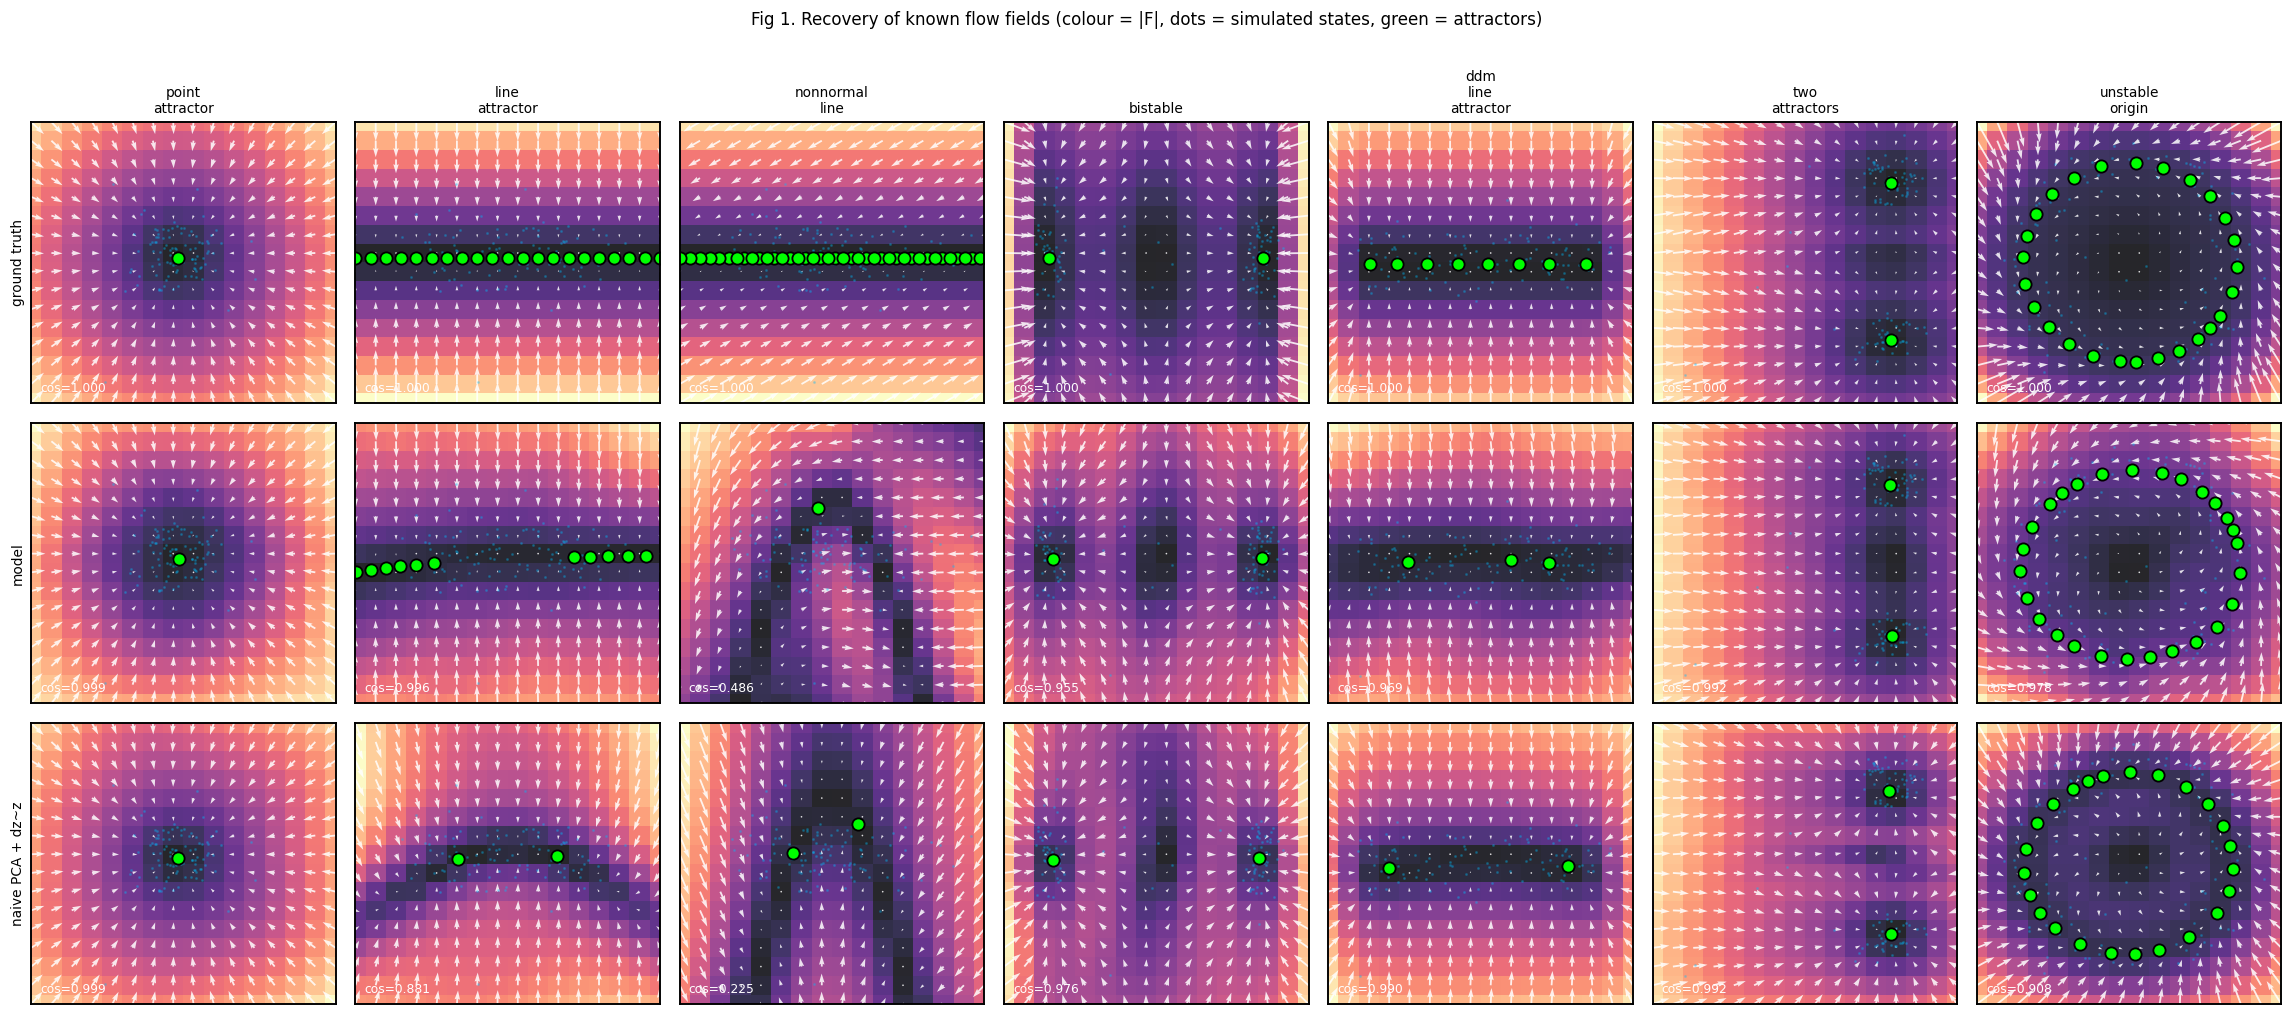

In [4]:
# ---- FIGURE 1: true vs recovered flow fields ----
names = [n for n in VAL_SYSTEMS if n in VAL]
fig, axes = plt.subplots(3, len(names), figsize=(3.0 * len(names), 9.2), squeeze=False)
for j, name in enumerate(names):
    V = VAL[name]
    Ztrue = V["Ztrue"]
    lims = dy.limits_from_points(Ztrue, pad=0.1)
    vis = dy.occupancy_mask(Ztrue, lims, grid_n=VAL_GRID, min_count=5, dilate=1)
    _, _, axg = dy.make_grid(lims, VAL_GRID)
    gx, gy = np.meshgrid(np.linspace(*lims[0], 16), np.linspace(*lims[1], 16),
                         indexing="ij")
    P = np.stack([gx.ravel(), gy.ravel()], axis=-1)
    for i, (lab, fld) in enumerate([("ground truth", V["system"]),
                                    ("model", V["f_model"]),
                                    ("naive PCA + dz~z", V["f_naive"])]):
        ax = axes[i][j]
        Vf = fld(P)
        sp = dy.speed(Vf).reshape(gx.shape)
        ax.pcolormesh(gx, gy, sp, cmap="magma", shading="auto", alpha=0.85)
        ax.quiver(gx, gy, Vf[:, 0].reshape(gx.shape), Vf[:, 1].reshape(gx.shape),
                  color="w", alpha=0.85, width=0.006, scale=None)
        ax.scatter(Ztrue[::200, 0], Ztrue[::200, 1], s=1, c="deepskyblue", alpha=0.25)
        at, _ = dy.find_attractors_by_simulation(fld, lims, dt=PC.dt, n_steps=800,
                                                 grid_n=21, merge_dist=0.15)
        for p in at:
            if dy.lookup_mask(vis, axg, p.z):
                ax.plot(p.z[0], p.z[1], "o", mfc="lime", mec="k", ms=8, mew=1.2)
        row = val_df[(val_df.system == name) & (val_df.label ==
                     ["truth", "model", "naive_pca"][i])]
        c = float(row.cosine.iloc[0]) if len(row) else np.nan
        ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1])
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(name.replace("_", "\n"), fontsize=9)
        if j == 0:
            ax.set_ylabel(lab, fontsize=9)
        ax.text(0.03, 0.03, f"cos={c:.3f}", transform=ax.transAxes, fontsize=8,
                color="w", va="bottom")
fig.suptitle("Fig 1. Recovery of known flow fields (colour = |F|, dots = simulated states, "
             "green = attractors)", y=1.001, fontsize=11)
fig.tight_layout(); plt.show()

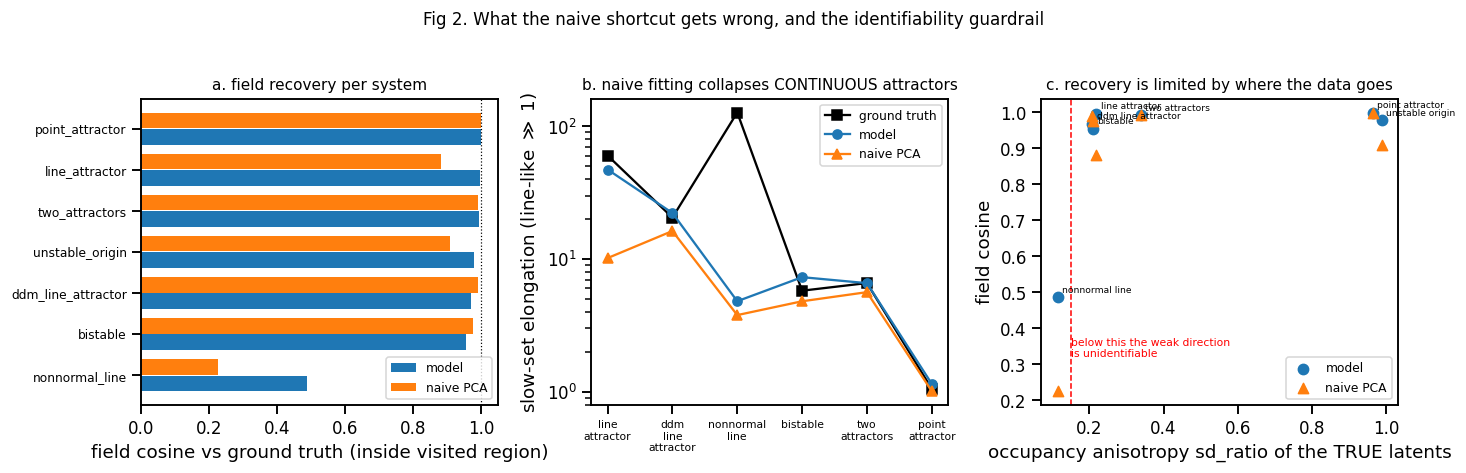

In [5]:
# ---- FIGURE 2: the two failure modes, side by side ----
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

ax = axes[0]
sub = val_df[val_df.label != "truth"].pivot_table(index="system", columns="label",
                                                  values="cosine")
sub = sub.sort_values("model")
y = np.arange(len(sub))
ax.barh(y - 0.2, sub["model"], height=0.38, label="model", color="tab:blue")
ax.barh(y + 0.2, sub["naive_pca"], height=0.38, label="naive PCA", color="tab:orange")
ax.set_yticks(y); ax.set_yticklabels(sub.index, fontsize=8)
ax.set_xlabel("field cosine vs ground truth (inside visited region)")
ax.axvline(1.0, color="k", lw=0.8, ls=":")
ax.legend(fontsize=8); ax.set_title("a. field recovery per system", fontsize=10)

ax = axes[1]
sub2 = val_df.pivot_table(index="system", columns="label", values="slow_elongation")
sub2 = sub2.loc[[s for s in ["line_attractor", "ddm_line_attractor", "nonnormal_line",
                             "bistable", "two_attractors", "point_attractor"]
                 if s in sub2.index]]
x = np.arange(len(sub2))
ax.plot(x, sub2["truth"], "ks-", label="ground truth", ms=6)
ax.plot(x, sub2["model"], "o-", color="tab:blue", label="model")
ax.plot(x, sub2["naive_pca"], "^-", color="tab:orange", label="naive PCA")
ax.set_yscale("log"); ax.set_xticks(x)
ax.set_xticklabels([s.replace("_", "\n") for s in sub2.index], fontsize=7)
ax.set_ylabel("slow-set elongation (line-like $\\gg$ 1)")
ax.legend(fontsize=8)
ax.set_title("b. naive fitting collapses CONTINUOUS attractors", fontsize=10)

ax = axes[2]
ok = val_df[val_df.label == "model"]
ax.scatter(ok.sd_ratio, ok.cosine, s=45, c="tab:blue", label="model")
nv = val_df[val_df.label == "naive_pca"]
ax.scatter(nv.sd_ratio, nv.cosine, s=45, c="tab:orange", marker="^", label="naive PCA")
for _, q in ok.iterrows():
    ax.annotate(q.system.replace("_", " "), (q.sd_ratio, q.cosine), fontsize=6,
                xytext=(3, 3), textcoords="offset points")
ax.axvline(0.15, color="r", ls="--", lw=1)
ax.text(0.152, 0.32, "below this the weak direction\nis unidentifiable", fontsize=7, color="r")
ax.set_xlabel("occupancy anisotropy sd_ratio of the TRUE latents")
ax.set_ylabel("field cosine")
ax.legend(fontsize=8); ax.set_title("c. recovery is limited by where the data goes", fontsize=10)
fig.suptitle("Fig 2. What the naive shortcut gets wrong, and the identifiability guardrail",
             y=1.02, fontsize=11)
fig.tight_layout(); plt.show()

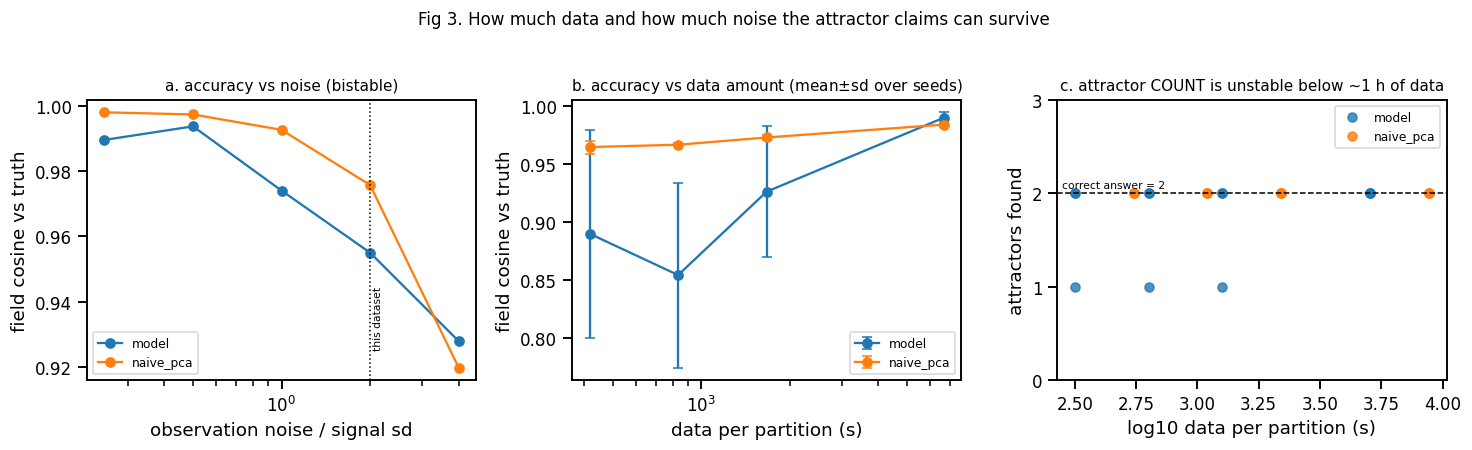

Read c. carefully: at per-day data volumes a single fit's attractor count flips
between 1 and 2 across seeds, so every attractor claim below is made from a
seed ENSEMBLE and reported with its across-seed spread.


In [6]:
# ---- FIGURE 3: noise and data-amount sweeps (does an attractor count survive?) ----
SWEEP_NOISE = [0.25, 0.5, 1.0, 2.0, 4.0]
SWEEP_NSEG = [50, 100, 200, 800]
sweep_rows = []
if RUN_VALIDATION:
    bist = VAL_SYSTEMS["bistable"]
    for noise in SWEEP_NOISE:
        s_v, t_v, r_v = val_fit(bist, tag=f"noise_{noise}", obs_noise=noise)
        F = val_fields(s_v, t_v, r_v)
        for lab, fld in [("model", F["f_model"]), ("naive_pca", F["f_naive"])]:
            q = val_score(fld, bist, F["Ztrue"], label=lab)
            q.update(sweep="noise", x=noise, seed=0)
            sweep_rows.append(q)
        dy.free(r_v)
    for nseg in SWEEP_NSEG:
        for sd in SEEDS:
            s_v, t_v, r_v = val_fit(bist, tag=f"nseg_{nseg}_s{sd}", n_segments=nseg, seed=sd)
            F = val_fields(s_v, t_v, r_v)
            for lab, fld in [("model", F["f_model"]), ("naive_pca", F["f_naive"])]:
                q = val_score(fld, bist, F["Ztrue"], label=lab)
                q.update(sweep="nseg", x=nseg, seed=sd)
                sweep_rows.append(q)
            dy.free(r_v)
    sweep_df = pd.DataFrame(sweep_rows)
    sweep_df.to_csv(VAL_OUT / "sweeps.csv", index=False)
else:
    sweep_df = pd.read_csv(VAL_OUT / "sweeps.csv")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
nz = sweep_df[sweep_df.sweep == "noise"]
ax = axes[0]
for lab, col in [("model", "tab:blue"), ("naive_pca", "tab:orange")]:
    s = nz[nz.label == lab].sort_values("x")
    ax.plot(s.x, s.cosine, "o-", color=col, label=lab)
ax.axvline(2.0, color="k", ls=":", lw=1)
ax.text(2.05, ax.get_ylim()[0] + 0.01, "this dataset", fontsize=7, rotation=90)
ax.set_xscale("log"); ax.set_xlabel("observation noise / signal sd")
ax.set_ylabel("field cosine vs truth"); ax.legend(fontsize=8)
ax.set_title("a. accuracy vs noise (bistable)", fontsize=10)

ns = sweep_df[sweep_df.sweep == "nseg"]
ax = axes[1]
for lab, col in [("model", "tab:blue"), ("naive_pca", "tab:orange")]:
    s = ns[ns.label == lab].groupby("x").cosine.agg(["mean", "std"]).reset_index()
    ax.errorbar(s.x * 50 / PC.sr, s["mean"], yerr=s["std"], fmt="o-", color=col,
                capsize=3, label=lab)
ax.set_xscale("log"); ax.set_xlabel("data per partition (s)")
ax.set_ylabel("field cosine vs truth"); ax.legend(fontsize=8)
ax.set_title("b. accuracy vs data amount (mean$\\pm$sd over seeds)", fontsize=10)

ax = axes[2]
for lab, col, off in [("model", "tab:blue", -0.12), ("naive_pca", "tab:orange", 0.12)]:
    s = ns[ns.label == lab]
    xs = np.log10(s.x * 50 / PC.sr) + off
    ax.scatter(xs, s.n_attractors, s=35, c=col, alpha=0.8, label=lab)
ax.axhline(2, color="k", ls="--", lw=1)
ax.text(ax.get_xlim()[0] + 0.02, 2.05, "correct answer = 2", fontsize=7)
ax.set_xlabel("log10 data per partition (s)")
ax.set_ylabel("attractors found"); ax.set_yticks([0, 1, 2, 3]); ax.legend(fontsize=8)
ax.set_title("c. attractor COUNT is unstable below ~1 h of data", fontsize=10)
fig.suptitle("Fig 3. How much data and how much noise the attractor claims can survive",
             y=1.02, fontsize=11)
fig.tight_layout(); plt.show()

print("Read c. carefully: at per-day data volumes a single fit's attractor count flips")
print("between 1 and 2 across seeds, so every attractor claim below is made from a")
print("seed ENSEMBLE and reported with its across-seed spread.")

## 2. Data budget: what can actually be fitted?

Section 1 established that a single fit needs roughly **6700 s** of data before its attractor count
stops flipping between seeds. This section puts the available data next to that number, per day and
per condition, and makes the **trial-length imbalance** explicit — hits last a few seconds, misses
always exactly 20 s, so an unweighted fit would estimate the field mostly from failure trials.

In [7]:
import cursor_analysis_utils as ca; importlib.reload(ca)

VIABLE_SEC = 6700.0     # from section 1: below this a single fit's attractor count flips
BUDGET_MICE = ["mouse_0403L", "mouse_0322R"]

bud_path = OUT.parent.parent / "dynamics_budget.csv"
if bud_path.exists():
    bud = pd.read_csv(bud_path)
else:
    rows = []
    for mouse in BUDGET_MICE:
        rm = na.open_mouse(rfs, DATA_ROOT, mouse)
        for di, day in enumerate(na.get_day_list(rm)):
            trials = na.get_true_bmi_trials(na.get_trials_df(rm, day))
            if len(trials) == 0:
                continue
            T = len(ca.get_decoder_df(rm, day))          # == n neural frames
            rew = na.get_active_reward_frames(rm, day)
            facs = np.unique(trials.factor[np.isfinite(trials.factor)])
            cor = na.correct_trial_intervals(trials, T)
            inc = na.incorrect_trial_intervals(trials, T, window_sec=MISS_SEC, sr=int(SR))
            bas = na.baseline_intervals(trials, T, exclude_sec=10.0, sr=SR,
                                        min_len_sec=1.0, reward_frames=rew,
                                        miss_dur_sec=MISS_SEC)
            med = np.median([e - s for s, e in cor]) if cor else np.nan
            ie, il = dy.split_incorrect_intervals(inc, int(med)) if (cor and inc) else ([], [])
            durs = np.array([(e - s) / SR for s, e in cor])
            rows.append(dict(
                mouse=mouse, day=day, day_i=di,
                phase="remap" if facs.size > 1 else "stable",
                n_trials=len(trials), hit_rate=float(np.nanmean(trials.success)),
                correct_sec=sum(e - s for s, e in cor) / SR,
                incorrect_sec=sum(e - s for s, e in inc) / SR,
                inc_early_sec=sum(e - s for s, e in ie) / SR,
                inc_late_sec=sum(e - s for s, e in il) / SR,
                baseline_sec=sum(e - s for s, e in bas) / SR,
                correct_med_sec=float(med / SR) if np.isfinite(med) else np.nan,
                correct_dur_p10=float(np.percentile(durs, 10)) if len(durs) else np.nan,
                correct_dur_p90=float(np.percentile(durs, 90)) if len(durs) else np.nan))
    bud = pd.DataFrame(rows)
    bud.to_csv(bud_path, index=False)

bud["total_sec"] = bud[["correct_sec", "inc_early_sec", "inc_late_sec", "baseline_sec"]].sum(1)
print(bud.groupby(["mouse", "phase"])[["correct_sec", "incorrect_sec", "baseline_sec",
                                       "total_sec", "hit_rate"]].median().round(1).to_string())
print(f"\ndays reaching {VIABLE_SEC:.0f} s on their own: "
      f"{(bud.total_sec >= VIABLE_SEC).sum()} of {len(bud)}")

                    correct_sec  incorrect_sec  baseline_sec  total_sec  hit_rate
mouse       phase                                                                
mouse_0322R stable        656.5         1200.0         376.8     2280.4       0.6
mouse_0403L remap        1101.7          260.0        1074.0     2681.2       1.0
            stable        944.1          310.0         545.2     2061.8       0.9

days reaching 6700 s on their own: 0 of 65


C:\Users\alireza\AppData\Local\Temp\ipykernel_22160\217095561.py:43: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  bud["total_sec"] = bud[["correct_sec", "inc_early_sec", "inc_late_sec", "baseline_sec"]].sum(1)


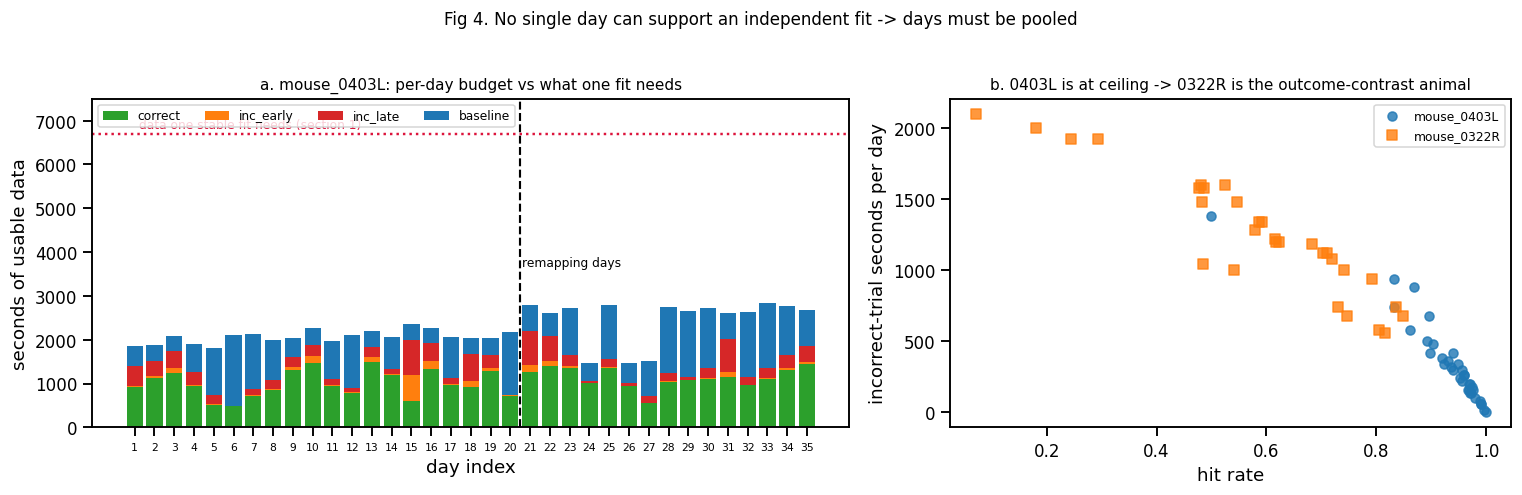

In [8]:
# ---- FIGURE 4: per-day budget against what one fit needs ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
sub = bud[bud.mouse == MOUSE].sort_values("day_i").reset_index(drop=True)
x = np.arange(len(sub))
bot = np.zeros(len(sub))
for k, col in [("correct_sec", "tab:green"), ("inc_early_sec", "tab:orange"),
               ("inc_late_sec", "tab:red"), ("baseline_sec", "tab:blue")]:
    ax.bar(x, sub[k], bottom=bot, color=col, label=k.replace("_sec", ""), width=0.82)
    bot += sub[k].values
n_rem = int((sub.phase == "remap").sum())
if n_rem:
    ax.axvline(len(sub) - n_rem - 0.5, color="k", ls="--", lw=1.4)
    ax.text(len(sub) - n_rem - 0.4, VIABLE_SEC * 0.55, "remapping days", fontsize=8)
ax.axhline(VIABLE_SEC, color="crimson", ls=":", lw=1.6)
ax.text(0.2, VIABLE_SEC * 1.02, "data one stable fit needs (section 1)",
        color="crimson", fontsize=8)
ax.set_ylim(0, VIABLE_SEC * 1.12)
ax.set_xticks(x); ax.set_xticklabels(sub.day_i, fontsize=7)
ax.set_xlabel("day index"); ax.set_ylabel("seconds of usable data")
ax.set_title(f"a. {MOUSE}: per-day budget vs what one fit needs", fontsize=10)
ax.legend(fontsize=8, ncol=4, loc="upper left")

ax = axes[1]
for mouse, mk in [("mouse_0403L", "o"), ("mouse_0322R", "s")]:
    s = bud[bud.mouse == mouse]
    ax.scatter(s.hit_rate, s.incorrect_sec, marker=mk, s=35, alpha=0.8, label=mouse)
ax.set_xlabel("hit rate"); ax.set_ylabel("incorrect-trial seconds per day")
ax.set_title("b. 0403L is at ceiling -> 0322R is the outcome-contrast animal", fontsize=10)
ax.legend(fontsize=8)
fig.suptitle("Fig 4. No single day can support an independent fit -> days must be pooled",
             y=1.02, fontsize=11)
fig.tight_layout(); plt.show()

c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type pandas_dataframe.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")


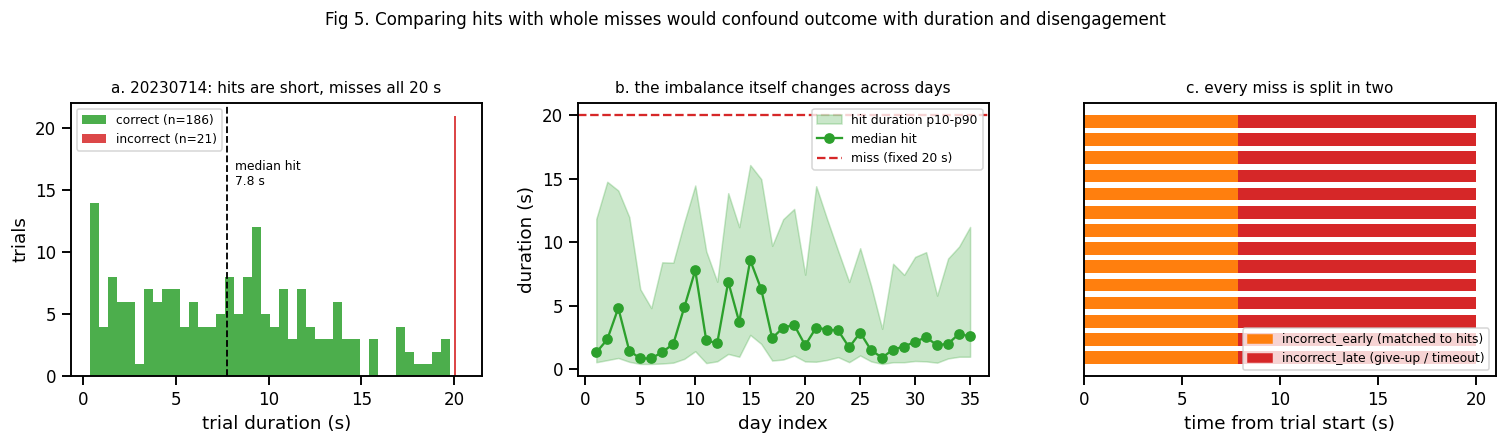

In [9]:
# ---- FIGURE 5: the trial-length confound, made explicit ----
day_ex = days[EXAMPLE_DAY_I]
tr_ex = na.get_true_bmi_trials(na.get_trials_df(r, day_ex))
T_ex = len(ca.get_decoder_df(r, day_ex))
cor_ex = na.correct_trial_intervals(tr_ex, T_ex)
inc_ex = na.incorrect_trial_intervals(tr_ex, T_ex, window_sec=MISS_SEC, sr=int(SR))
dc = np.array([(e - s) / SR for s, e in cor_ex])
di_ = np.array([(e - s) / SR for s, e in inc_ex])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axes[0]
ax.hist(dc, bins=40, color="tab:green", alpha=0.85, label=f"correct (n={len(dc)})")
ax.hist(di_, bins=10, color="tab:red", alpha=0.85, label=f"incorrect (n={len(di_)})")
ax.axvline(np.median(dc), color="k", ls="--", lw=1.2)
ax.text(np.median(dc) * 1.05, ax.get_ylim()[1] * 0.7, f"median hit\n{np.median(dc):.1f} s",
        fontsize=8)
ax.set_xlabel("trial duration (s)"); ax.set_ylabel("trials")
ax.set_title(f"a. {day_ex}: hits are short, misses all 20 s", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
s = bud[bud.mouse == MOUSE].sort_values("day_i")
ax.fill_between(s.day_i, s.correct_dur_p10, s.correct_dur_p90, alpha=0.25,
                color="tab:green", label="hit duration p10-p90")
ax.plot(s.day_i, s.correct_med_sec, "o-", color="tab:green", label="median hit")
ax.axhline(MISS_SEC, color="tab:red", ls="--", label="miss (fixed 20 s)")
ax.set_xlabel("day index"); ax.set_ylabel("duration (s)")
ax.set_title("b. the imbalance itself changes across days", fontsize=10)
ax.legend(fontsize=8)

ax = axes[2]
med_b = dy.median_duration_bins(dy.intervals_to_bins(cor_ex, PC.bin_frames))
for k, (s0, e0) in enumerate(inc_ex[:14]):
    dur = (e0 - s0) / SR
    cut = min(med_b / PC.sr, dur)
    ax.barh(k, cut, color="tab:orange", height=0.7)
    ax.barh(k, dur - cut, left=cut, color="tab:red", height=0.7)
ax.set_yticks([]); ax.set_xlabel("time from trial start (s)")
ax.set_title("c. every miss is split in two", fontsize=10)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="tab:orange"),
                   plt.Rectangle((0, 0), 1, 1, color="tab:red")],
          labels=["incorrect_early (matched to hits)", "incorrect_late (give-up / timeout)"],
          fontsize=8, loc="lower right")
fig.suptitle("Fig 5. Comparing hits with whole misses would confound outcome with "
             "duration and disengagement", y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

## 3. Preprocessing and nuisance, checked rather than assumed

Three choices get evidence here: the **variance-stabilising transform**, the **time step**, and how
much the **nuisance model** should remove. The last panel is a control, not a preprocessing step: it
asks whether locomotion, licking or imaging-motion metrics differ systematically *between the
conditions we are about to compare*. Where they do, that contrast needs the robustness refit with
the offending regressor included — which is how `motionCorrection` is used here, rather than being
regressed out by default.

c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type numpy_array.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")


transform  skew  kurtosis  hetero_slope  frac_zero
      raw 4.132    29.461         1.438      0.122
     sqrt 1.550     4.800         0.879      0.122
    log1p 1.352     3.286         0.829      0.122


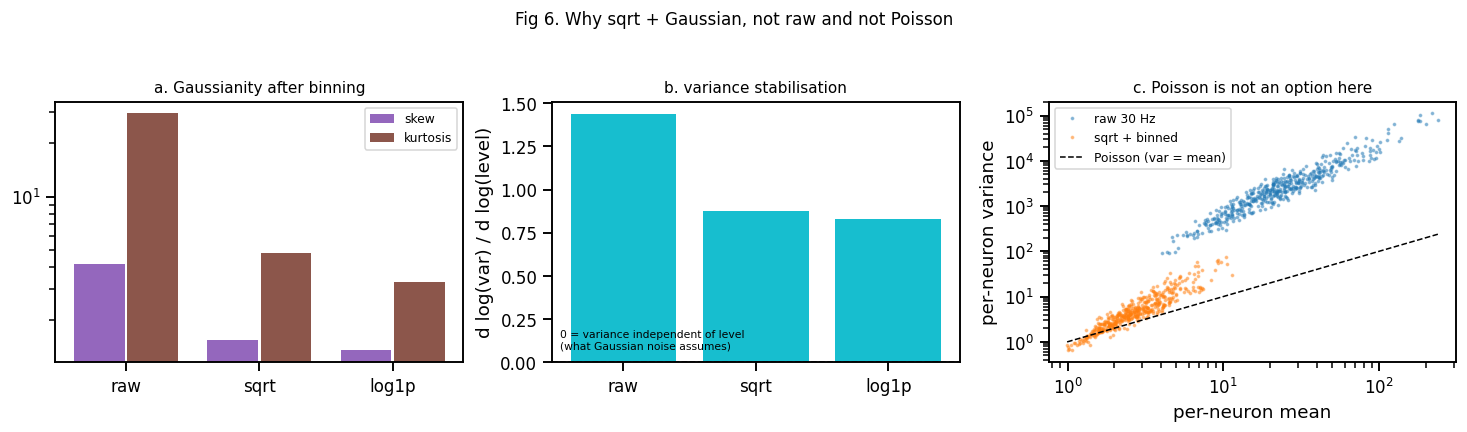

In [10]:
# ---- FIGURE 6: which transform? ----
Xraw_ex = na.load_neural(r, day_ex)
rew_ex = na.get_active_reward_frames(r, day_ex)
bas_ex = na.baseline_intervals(tr_ex, Xraw_ex.shape[1], exclude_sec=10.0, sr=SR,
                               min_len_sec=1.0, reward_frames=rew_ex, miss_dur_sec=MISS_SEC)


def hetero_slope(Xb, step=3):
    '''d log(residual variance) / d log(level): 0 = homoscedastic, 1 = Poisson-like.'''
    from scipy.ndimage import uniform_filter1d
    lev = uniform_filter1d(Xb, size=9, axis=1, mode="nearest")
    res = Xb - lev
    out = []
    for i in range(0, Xb.shape[0], step):
        q = np.unique(np.quantile(lev[i], np.linspace(0, 1, 11)))
        if q.size < 5:
            continue
        idx = np.clip(np.digitize(lev[i], q[1:-1]), 0, q.size - 2)
        mv = [(lev[i][idx == b].mean(), res[i][idx == b].var())
              for b in range(q.size - 1)
              if (idx == b).sum() > 30 and lev[i][idx == b].mean() > 1e-6]
        if len(mv) >= 4:
            mv = np.array(mv); ok = mv[:, 1] > 1e-12
            if ok.sum() >= 4:
                out.append(stats.linregress(np.log10(mv[ok, 0]),
                                            np.log10(mv[ok, 1])).slope)
    return float(np.median(out)) if out else np.nan


tf_rows = []
for tname in ["none", "sqrt", "log1p"]:
    Xb_t = dy.bin_matrix(dy.transform_activity(Xraw_ex, dy.PreprocConfig(transform=tname)),
                         PC.bin_frames)
    tf_rows.append(dict(transform="raw" if tname == "none" else tname,
                        skew=float(np.median(stats.skew(Xb_t, axis=1))),
                        kurtosis=float(np.median(stats.kurtosis(Xb_t, axis=1))),
                        hetero_slope=hetero_slope(Xb_t),
                        frac_zero=float(np.mean(Xb_t == 0))))
    del Xb_t
tf = pd.DataFrame(tf_rows)
print(tf.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
xs = np.arange(len(tf))
ax = axes[0]
ax.bar(xs - 0.2, tf["skew"], width=0.38, label="skew", color="tab:purple")
ax.bar(xs + 0.2, tf["kurtosis"], width=0.38, label="kurtosis", color="tab:brown")
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(tf["transform"])
ax.set_title("a. Gaussianity after binning", fontsize=10); ax.legend(fontsize=8)
ax = axes[1]
ax.bar(xs, tf["hetero_slope"], color="tab:cyan")
ax.axhline(0, color="k", ls="--", lw=1)
ax.text(0.02, 0.05, "0 = variance independent of level\n(what Gaussian noise assumes)",
        transform=ax.transAxes, fontsize=7)
ax.set_xticks(xs); ax.set_xticklabels(tf["transform"])
ax.set_ylabel("d log(var) / d log(level)")
ax.set_title("b. variance stabilisation", fontsize=10)
ax = axes[2]
Xb_s = dy.bin_matrix(dy.transform_activity(Xraw_ex, PC), PC.bin_frames)
mu, va = Xraw_ex.mean(1), Xraw_ex.var(1)
ok = mu > 1e-9
ax.loglog(mu[ok], va[ok], ".", ms=3, alpha=0.4, label="raw 30 Hz")
mu2, va2 = Xb_s.mean(1), Xb_s.var(1)
ok2 = mu2 > 1e-9
ax.loglog(mu2[ok2], va2[ok2], ".", ms=3, alpha=0.4, label=f"{PC.transform} + binned")
lo, hi = float(np.nanmin(mu2[ok2])), float(np.nanmax(mu[ok]))
ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="Poisson (var = mean)")
ax.set_xlabel("per-neuron mean"); ax.set_ylabel("per-neuron variance")
ax.legend(fontsize=8); ax.set_title("c. Poisson is not an option here", fontsize=10)
fig.suptitle("Fig 6. Why sqrt + Gaussian, not raw and not Poisson", y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

 bin_frames    dt_ms condition  flow_r2  white_frac  n_pairs
          1  33.3333   correct   0.1479      0.2027    43856
          1  33.3333  baseline   0.1904      0.2027    11175
          2  66.6667   correct   0.1185      0.1472    21832
          2  66.6667  baseline   0.1731      0.1472     5565
          5 166.6667   correct   0.1472      0.1089     8612
          5 166.6667  baseline   0.1703      0.1089     2203
         10 333.3333   correct   0.1564      0.0720     4199
         10 333.3333  baseline   0.1585      0.0720     1080
         15 500.0000   correct   0.1825      0.0760     2732
         15 500.0000  baseline   0.1583      0.0760      707


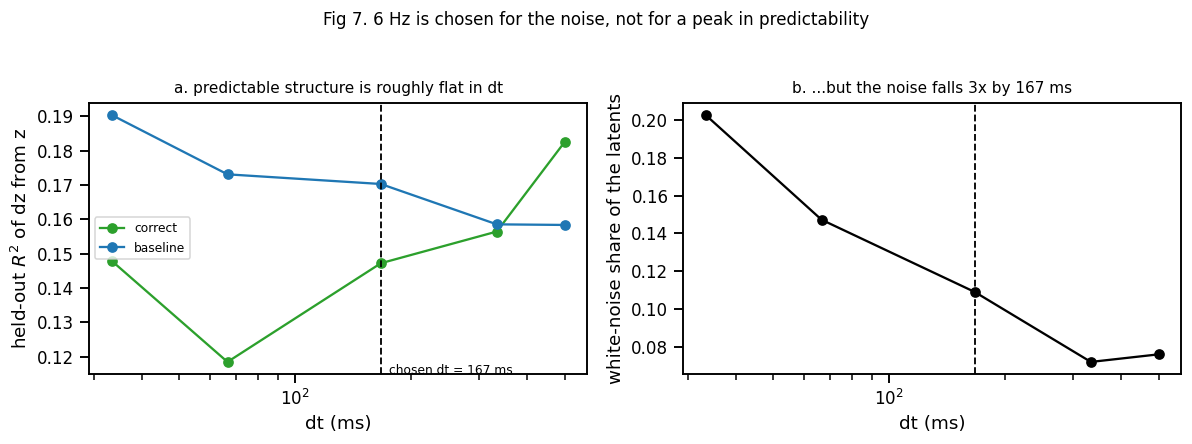

In [11]:
# ---- FIGURE 7: which time step? ----
# NOTE both curves must use the SAME per-neuron scaling, or the comparison is
# meaningless: MAD scaling amplifies mostly-zero neurons, and at 30 Hz (59% zeros)
# that alone pushed the latents' white-noise share from 0.20 to 0.75.
from sklearn.linear_model import Ridge

dt_path = OUT / "dt_sweep.csv"
if dt_path.exists():
    dts = pd.read_csv(dt_path)
else:
    rows = []
    for b in [1, 2, 5, 10, 15]:
        pcx = dy.PreprocConfig(bin_frames=b, transform=PC.transform, scale_mode="std")
        Xb = dy.bin_matrix(dy.transform_activity(Xraw_ex, pcx), b)
        Xb = Xb / dy.neuron_scales(Xb, pcx)[:, None]
        Tb = Xb.shape[1]
        w, V = np.linalg.eigh(np.cov(Xb))
        Z = (V[:, ::-1][:, :6].T @ Xb).T
        Z = Z / Z.std(0, keepdims=True)
        wf = float(np.mean(dy.white_noise_fraction(Z.T)))
        tb = na.bin_trials(tr_ex, b); rwb = na.bin_frames(rew_ex, b)
        conds = {"correct": na.correct_trial_intervals(tb, Tb),
                 "baseline": na.baseline_intervals(tb, Tb, exclude_sec=10.0, sr=pcx.sr,
                                                   min_len_sec=1.0, reward_frames=rwb,
                                                   miss_dur_sec=MISS_SEC)}
        for cname, ivs in conds.items():
            X, Y, S = [], [], []
            for k, (s0, e0) in enumerate(ivs):
                z = Z[int(s0):int(e0)]
                if z.shape[0] < 4:
                    continue
                X.append(z[:-1]); Y.append(np.diff(z, axis=0) / pcx.dt)
                S.append(np.full(z.shape[0] - 1, k))
            if not X:
                continue
            X, Y, S = np.concatenate(X), np.concatenate(Y), np.concatenate(S)
            segs = np.unique(S); rng = np.random.default_rng(0); rng.shuffle(segs)
            num = den = 0.0
            for f in np.array_split(segs, 5):
                te = np.isin(S, f); trn = ~te
                if trn.sum() < 50 or te.sum() < 20:
                    continue
                mdl = Ridge(alpha=1.0).fit(X[trn], Y[trn])
                num += ((Y[te] - mdl.predict(X[te])) ** 2).sum()
                den += ((Y[te] - Y[trn].mean(0)) ** 2).sum()
            rows.append(dict(bin_frames=b, dt_ms=1000 * b / SR, condition=cname,
                             flow_r2=1 - num / max(den, 1e-9), white_frac=wf,
                             n_pairs=len(Y)))
        del Xb, Z
    dts = pd.DataFrame(rows)
    dts.to_csv(dt_path, index=False)
print(dts.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
ax = axes[0]
for cname, col in [("correct", "tab:green"), ("baseline", "tab:blue")]:
    s = dts[dts.condition == cname].sort_values("dt_ms")
    ax.plot(s.dt_ms, s.flow_r2, "o-", color=col, label=cname)
ax.axvline(1000 * PC.bin_frames / SR, color="k", ls="--", lw=1.2)
ax.text(1000 * PC.bin_frames / SR * 1.05, ax.get_ylim()[0],
        f"chosen dt = {1000 * PC.bin_frames / SR:.0f} ms", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("dt (ms)")
ax.set_ylabel("held-out $R^2$ of dz from z")
ax.set_title("a. predictable structure is roughly flat in dt", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
s = dts.drop_duplicates("dt_ms").sort_values("dt_ms")
ax.plot(s.dt_ms, s.white_frac, "ko-")
ax.axvline(1000 * PC.bin_frames / SR, color="k", ls="--", lw=1.2)
ax.set_xscale("log"); ax.set_xlabel("dt (ms)")
ax.set_ylabel("white-noise share of the latents")
ax.set_title("b. ...but the noise falls 3x by 167 ms", fontsize=10)
fig.suptitle("Fig 7. 6 Hz is chosen for the noise, not for a peak in predictability",
             y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type numpy_array.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")
c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type pandas_dataframe.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")


            model  n_pred     r2  unique_drift  unique_events  unique_covariates
drift only (used)       5 0.0069        0.0069            NaN                NaN
         + events      13 0.0296        0.0071         0.0192                NaN
      + behaviour      19 0.0606        0.0067         0.0125             0.0222
 + imaging motion      28 0.1297        0.0090         0.0073             0.0866

explainable ceiling (1 - white-noise share) = 0.510


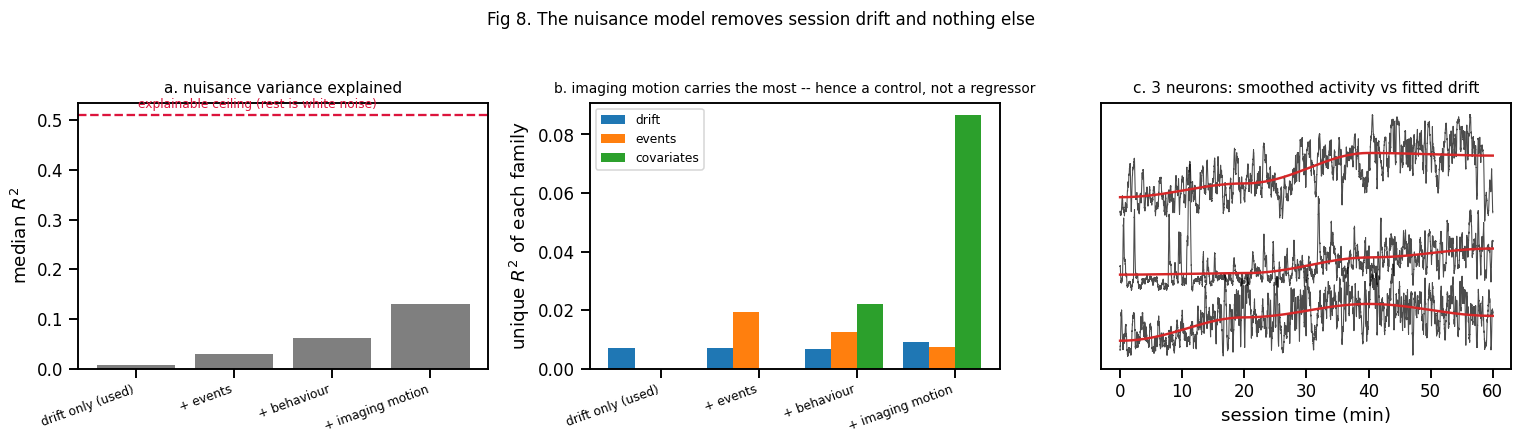

In [12]:
# ---- FIGURE 8 + 9: nuisance model, and the confound control ----
from scipy.ndimage import uniform_filter1d

Xb_ex = dy.bin_matrix(dy.transform_activity(Xraw_ex, PC), PC.bin_frames)
Tb_ex = Xb_ex.shape[1]
bc = np.unique(np.concatenate([np.arange(s, e) for s, e in bas_ex]) // PC.bin_frames)
bc = bc[bc < Tb_ex]
Xb_ex = Xb_ex / dy.neuron_scales(Xb_ex, PC, ref_cols=bc)[:, None]

ws = r["data_ws"][day_ex].load()
mc = r["extras"]["logger_dfs"][day_ex]["motionCorrection"].load()
zc_cols = [c for c in mc.columns if c.startswith("z_correlation")]


def binned(sig):
    return dy.bin_matrix(np.asarray(sig, float)[None, :], PC.bin_frames)[0][:Tb_ex]


tread, lick = binned(ws["treadmill"]), binned(ws["lickometer"])
mcx, mcy = binned(mc["xShift"]), binned(mc["yShift"])
zcorr = binned(mc[zc_cols].mean(axis=1))
start_b = na.bin_frames(tr_ex.start[np.isfinite(tr_ex.start)], PC.bin_frames)
rew_b = na.bin_frames(rew_ex, PC.bin_frames)
n_drift = dy.n_drift_for_session(Tb_ex, PC.sr, minutes_per_basis=15.0)

nu_rows, nuis_default = [], None
for label, comps, cov in [
        ("drift only (used)", ("drift",), None),
        ("+ events", ("drift", "events"), None),
        ("+ behaviour", ("drift", "events", "covariates"), {"tread": tread, "lick": lick}),
        ("+ imaging motion", ("drift", "events", "covariates"),
         {"tread": tread, "lick": lick, "mcx": mcx, "mcy": mcy, "zcorr": zcorr})]:
    D, nmz, grp = dy.build_nuisance_design(
        Tb_ex, components=comps, n_drift=n_drift, trial_start_bins=start_b,
        reward_bins=rew_b, covariates=cov)
    nmod = dy.fit_nuisance_baseline(Xb_ex, D, names=nmz, groups=grp)
    row = dict(model=label, n_pred=D.shape[1], r2=float(np.median(nmod.r2)))
    for g, v in nmod.group_r2.items():
        row[f"unique_{g}"] = float(np.median(v))
    nu_rows.append(row)
    if label.startswith("drift only"):
        nuis_default = nmod
nu = pd.DataFrame(nu_rows)
ceiling = float(np.median(1.0 - dy.white_noise_fraction(Xb_ex)))
print(nu.round(4).to_string(index=False))
print(f"\nexplainable ceiling (1 - white-noise share) = {ceiling:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axes[0]
ax.bar(np.arange(len(nu)), nu["r2"], color="tab:gray")
ax.axhline(ceiling, color="crimson", ls="--")
ax.text(0.02, ceiling * 1.03, "explainable ceiling (rest is white noise)",
        color="crimson", fontsize=8)
ax.set_xticks(np.arange(len(nu)))
ax.set_xticklabels(nu["model"], rotation=20, ha="right", fontsize=8)
ax.set_ylabel("median $R^2$"); ax.set_title("a. nuisance variance explained", fontsize=10)
ax = axes[1]
gcols = [c for c in nu.columns if c.startswith("unique_")]
w = 0.8 / max(len(gcols), 1)
for k, c in enumerate(gcols):
    ax.bar(np.arange(len(nu)) + k * w - 0.4, nu[c].fillna(0), width=w,
           label=c.replace("unique_", ""))
ax.set_xticks(np.arange(len(nu)))
ax.set_xticklabels(nu["model"], rotation=20, ha="right", fontsize=8)
ax.set_ylabel("unique $R^2$ of each family"); ax.legend(fontsize=8)
ax.set_title("b. imaging motion carries the most -- hence a control, not a regressor",
             fontsize=9)
ax = axes[2]
t_min = np.arange(Tb_ex) / PC.sr / 60
for k, i in enumerate(np.argsort(nuis_default.r2)[-3:]):
    ax.plot(t_min, uniform_filter1d(Xb_ex[i], 60) + k * 2.0, lw=0.7, color="k", alpha=0.7)
    ax.plot(t_min, np.log1p(np.exp(nuis_default.b[i])) + k * 2.0, lw=1.6, color="tab:red")
ax.set_xlabel("session time (min)"); ax.set_yticks([])
ax.set_title("c. 3 neurons: smoothed activity vs fitted drift", fontsize=10)
fig.suptitle("Fig 8. The nuisance model removes session drift and nothing else",
             y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

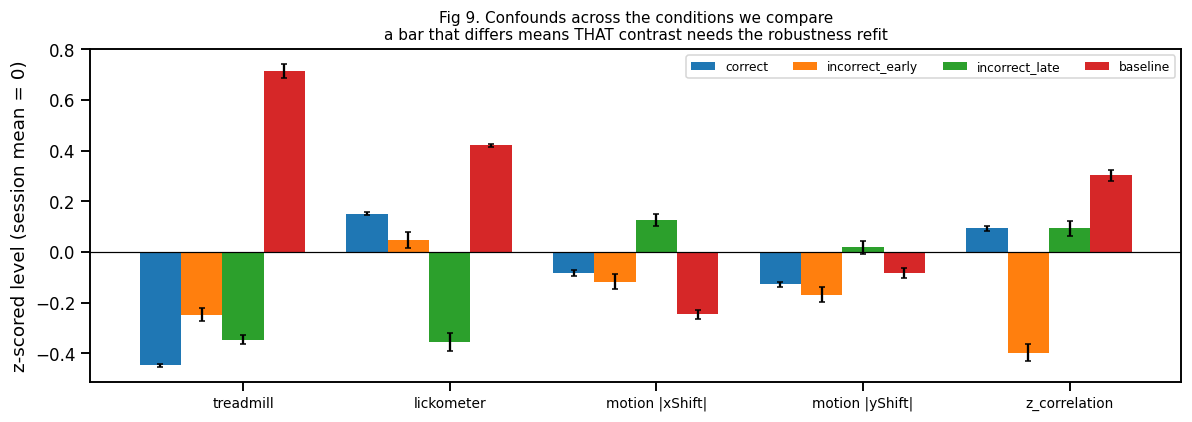

condition        baseline  correct  incorrect_early  incorrect_late
signal                                                             
lickometer          0.422    0.152            0.048          -0.355
motion |xShift|    -0.246   -0.082           -0.117           0.126
motion |yShift|    -0.083   -0.128           -0.169           0.019
treadmill           0.714   -0.448           -0.248          -0.346
z_correlation       0.302    0.093           -0.398           0.093

largest condition spread per signal (z units):
signal
treadmill          1.162
lickometer         0.777
z_correlation      0.700
motion |xShift|    0.372
motion |yShift|    0.187

Read this before section 6: locomotion differs most between baseline and task,
so the baseline-vs-task dynamics contrast is the one that most needs its control.


In [13]:
# ---- FIGURE 9: do the confounds differ across the conditions being compared? ----
cor_b = dy.intervals_to_bins(cor_ex, PC.bin_frames, Tb_ex)
inc_b = dy.intervals_to_bins(inc_ex, PC.bin_frames, Tb_ex)
bas_b = dy.intervals_to_bins(bas_ex, PC.bin_frames, Tb_ex)
ie_b, il_b = dy.split_incorrect_intervals(inc_b, dy.median_duration_bins(cor_b))
cond_iv = {"correct": cor_b, "incorrect_early": ie_b, "incorrect_late": il_b,
           "baseline": bas_b}
sigs = {"treadmill": tread, "lickometer": lick, "motion |xShift|": np.abs(mcx),
        "motion |yShift|": np.abs(mcy), "z_correlation": zcorr}

conf_rows = []
for signame, sig in sigs.items():
    sg = (sig - np.nanmean(sig)) / (np.nanstd(sig) + 1e-9)
    for cname, ivs in cond_iv.items():
        if not ivs:
            continue
        vals = np.concatenate([sg[int(s0):int(e0)] for s0, e0 in ivs])
        conf_rows.append(dict(signal=signame, condition=cname,
                              mean=float(np.nanmean(vals)),
                              sem=float(np.nanstd(vals) / max(np.sqrt(len(vals)), 1)),
                              n=len(vals)))
conf = pd.DataFrame(conf_rows)

fig, ax = plt.subplots(figsize=(11, 4.0))
cnames = list(cond_iv)
xs = np.arange(len(sigs)); w = 0.8 / len(cnames)
for k, cname in enumerate(cnames):
    s = conf[conf.condition == cname].set_index("signal").reindex(list(sigs))
    ax.bar(xs + k * w - 0.4, s["mean"], yerr=s["sem"], width=w, label=cname, capsize=2)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(xs); ax.set_xticklabels(list(sigs), fontsize=9)
ax.set_ylabel("z-scored level (session mean = 0)")
ax.legend(fontsize=8, ncol=4)
ax.set_title("Fig 9. Confounds across the conditions we compare\n"
             "a bar that differs means THAT contrast needs the robustness refit",
             fontsize=10)
fig.tight_layout(); plt.show()

piv = conf.pivot_table(index="signal", columns="condition", values="mean")
print(piv.round(3).to_string())
worst = (piv.max(axis=1) - piv.min(axis=1)).sort_values(ascending=False)
print("\nlargest condition spread per signal (z units):")
print(worst.round(3).to_string())
print("\nRead this before section 6: locomotion differs most between baseline and task,")
print("so the baseline-vs-task dynamics contrast is the one that most needs its control.")

## 4. The stable-phase flow field, end to end

Section 2 showed no single day reaches the data volume one fit needs, so the field is estimated
from **pooled stable days**, with day and condition available as embeddings for the comparisons in
sections 5 and 6. Everything here is the seed **ensemble**, and the across-seed spread is carried
forward as the noise floor for every later claim.

Two settings differ from the paper and both were measured, not assumed:

* `c_dyn` = 2.0 rather than FINDR's 0.1. At 0.1 the latent path partly tracks observation noise and
  the field is under-determined: across-seed field agreement 0.79, dynamics mismatch 8.7, and *no*
  trajectory converged. At 2.0: agreement 0.90, mismatch 1.5, trajectories converge — for 0.75 %
  worse reconstruction.
* `d` = 3, an interpretability choice. Held-out loss keeps improving past 5 (no elbow), so the cost
  of the choice is reported rather than hidden.

In [14]:
POOL_DAYS = 10          # stable days pooled for the section 4-6 field
POOL_EPOCHS = EPOCHS
PC.max_segment_bins = 100   # most hits are ~30-50 bins; trims padding in the latent loop

pool_days = STABLE_DAYS[:POOL_DAYS]
print(f"pooling {len(pool_days)} stable days", flush=True)

t0 = time.time()
_sets = []
for k, day in enumerate(pool_days):
    ss, _info = load_day_segments(day, day_label=k)
    _sets.append(ss)
pooled = dy.concat_segment_sets(_sets)
del _sets
COND = sorted({m["condition"] for m in pooled.meta})
CODE = {c: i for i, c in enumerate(COND)}
print(f"POOLED: {pooled.summary()} | {pooled.mask.sum() / PC.sr:.0f} s "
      f"| Y {pooled.Y.shape} ({pooled.Y.nbytes / 1e9:.2f} GB) | {time.time() - t0:.0f}s")
print("conditions:", COND)

# one split reused by every variant and seed, so comparisons are like-for-like
POOL_TR, POOL_VA = dy.split_train_val(pooled, val_frac=0.2, seed=0)
SEG_W = dy.time_balanced_weights(pooled, "condition")
print(f"train/val = {POOL_TR.size}/{POOL_VA.size} segments")

pooling 10 stable days


c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type numpy_array.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")
c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type pandas_dataframe.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")


POOLED: 2369 segments, 118524 valid samples, day:10 levels, condition:4 levels | 19754 s | Y (2369, 100, 468) (0.44 GB) | 35s
conditions: ['baseline', 'correct', 'incorrect_early', 'incorrect_late']
train/val = 1894/475 segments


In [15]:
# ---- fit the shared field at several seeds, then put them all in seed 0's frame ----
pool_fits = [fit_cached(pooled, tag=f"pool{len(pool_days)}", d=D_ANALYSIS, seed=s,
                        epochs=POOL_EPOCHS, train_idx=POOL_TR, val_idx=POOL_VA)
             for s in SEEDS]
m0 = pool_fits[0].model
FR = canonical_frame(m0, pooled)
Zall, Zby, trf = FR["Zall"], FR["Z"], FR["transform"]
# rescale so |z1| <= 1, which is what makes the distance-based defaults meaningful
trf = dy.normalize_scale(trf, Zall, mode="pc1_span")
FR = dict(FR, transform=trf, Z=[trf.forward(z) for z in dy.infer_latents(m0, pooled)])
Zby = FR["Z"]; Zall = np.concatenate(Zby, axis=0)
FIELD0 = dy.field_fn(m0, transform=trf)

pool_fields = [FIELD0]
align_info = []
for f_i in pool_fits[1:]:
    tb, info = dy.align_models(m0, f_i.model)
    cb = dy.canonical_transform(f_i.model)
    comb = dy.LatentTransform(trf.A @ np.linalg.inv(FR["base_transform"].A) @ tb.A @ cb.A)
    pool_fields.append(dy.field_fn(f_i.model, transform=comb))
    align_info.append(info)
FIELD = dy.ensemble_field(pool_fields)

LIMS = dy.limits_from_points(Zall, pad=0.15)
RAD = dy.support_radius(Zall)
REF = Zall[::max(1, Zall.shape[0] // 4000)]
SPREAD = dy.field_spread(pool_fields, points=REF)
REP = dy.reproducible_subspace([f.model for f in pool_fits], angle_threshold_deg=30.0)
ANISO = dy.occupancy_anisotropy(Zall)
STATES = condition_states(pooled, FR)

print(f"reproducible latent dims: {REP['n_reproducible']} / {D_ANALYSIS} "
      f"(worst-pair angles {np.round(REP['angles_worst'], 1)} deg)")
print(f"across-seed field spread: cosine {SPREAD['mean_pairwise_cosine']:.4f}"
      f"+-{SPREAD['sd_pairwise_cosine']:.4f}, nrmse {SPREAD['mean_pairwise_nrmse']:.4f}")
print(f"occupancy: sd={np.round(ANISO['sd'], 3)} sd_ratio={ANISO['sd_ratio']:.3f} "
      f"PR={ANISO['participation']:.2f} | support radius {RAD:.4f}")
print(f"GUARDRAIL sd_ratio > 0.15: "
      f"{'OK' if ANISO['sd_ratio'] > 0.15 else 'FAIL - weak direction unidentifiable'}")
for c in COND:
    print(f"   {c:16s} {STATES[c].shape[0]:6d} states")

reproducible latent dims: 3 / 3 (worst-pair angles [0.7 1.  2. ] deg)
across-seed field spread: cosine 0.8954+-0.0660, nrmse 0.5342
occupancy: sd=[0.344 0.238 0.144] sd_ratio=0.419 PR=2.69 | support radius 0.1393
GUARDRAIL sd_ratio > 0.15: OK
   baseline          45207 states
   correct           55389 states
   incorrect_early    3026 states
   incorrect_late    14902 states


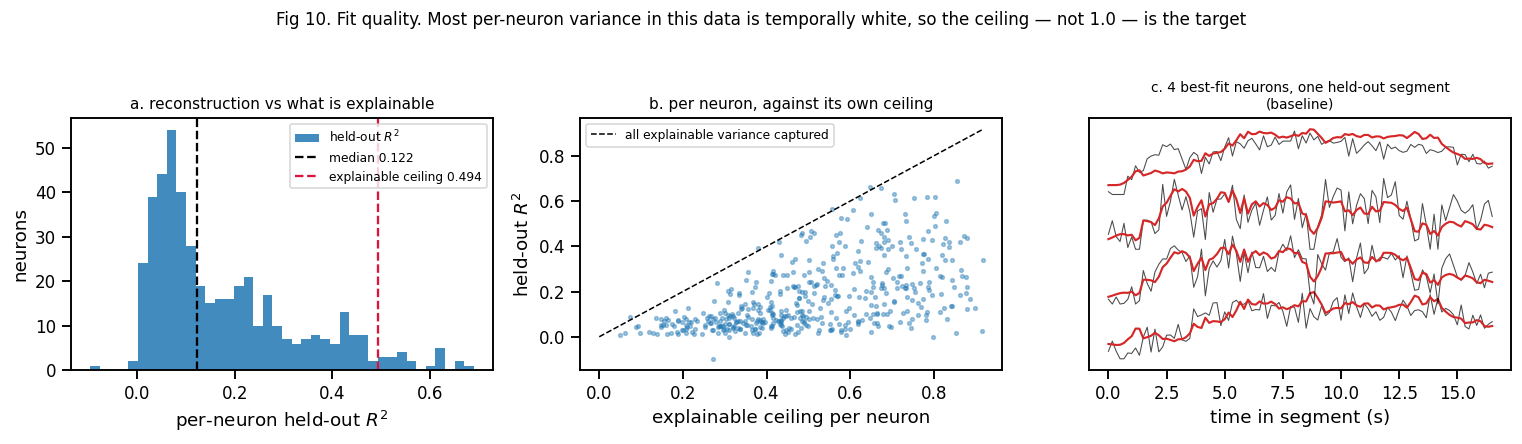

In [16]:
# ---- FIGURE 10: is the fit any good? ----
pred = dy.predict_activity(m0, pooled, POOL_VA)
obs = [pooled.Y[i, pooled.mask[i] > 0] for i in POOL_VA]
P_, O_ = np.concatenate(pred, 0), np.concatenate(obs, 0)
r2 = 1 - ((O_ - P_) ** 2).sum(0) / np.maximum(((O_ - O_.mean(0)) ** 2).sum(0), 1e-9)
ceil_per_neuron = 1.0 - dy.white_noise_fraction(O_.T)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axes[0]
ax.hist(r2, bins=40, color="tab:blue", alpha=0.85, label="held-out $R^2$")
ax.axvline(np.median(r2), color="k", ls="--",
           label=f"median {np.median(r2):.3f}")
ax.axvline(np.median(ceil_per_neuron), color="crimson", ls="--",
           label=f"explainable ceiling {np.median(ceil_per_neuron):.3f}")
ax.set_xlabel("per-neuron held-out $R^2$"); ax.set_ylabel("neurons")
ax.legend(fontsize=8)
ax.set_title("a. reconstruction vs what is explainable", fontsize=10)

ax = axes[1]
ax.scatter(ceil_per_neuron, r2, s=6, alpha=0.4)
lo, hi = 0, max(float(np.nanmax(ceil_per_neuron)), float(np.nanmax(r2)))
ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="all explainable variance captured")
ax.set_xlabel("explainable ceiling per neuron"); ax.set_ylabel("held-out $R^2$")
ax.legend(fontsize=8)
ax.set_title("b. per neuron, against its own ceiling", fontsize=10)

ax = axes[2]
seg = POOL_VA[np.argmax([pooled.mask[i].sum() for i in POOL_VA])]
kpick = np.argsort(r2)[-4:]
o_seg = pooled.Y[seg, pooled.mask[seg] > 0]
p_seg = dy.predict_activity(m0, pooled, np.array([seg]))[0]
tt = np.arange(o_seg.shape[0]) / PC.sr
for k, i in enumerate(kpick):
    ax.plot(tt, o_seg[:, i] + k * 3, color="k", lw=0.7, alpha=0.7)
    ax.plot(tt, p_seg[:, i] + k * 3, color="tab:red", lw=1.4)
ax.set_xlabel("time in segment (s)"); ax.set_yticks([])
ax.set_title(f"c. 4 best-fit neurons, one held-out segment\n"
             f"({pooled.meta[seg]['condition']})", fontsize=9)
fig.suptitle("Fig 10. Fit quality. Most per-neuron variance in this data is temporally "
             "white, so the ceiling — not 1.0 — is the target", y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

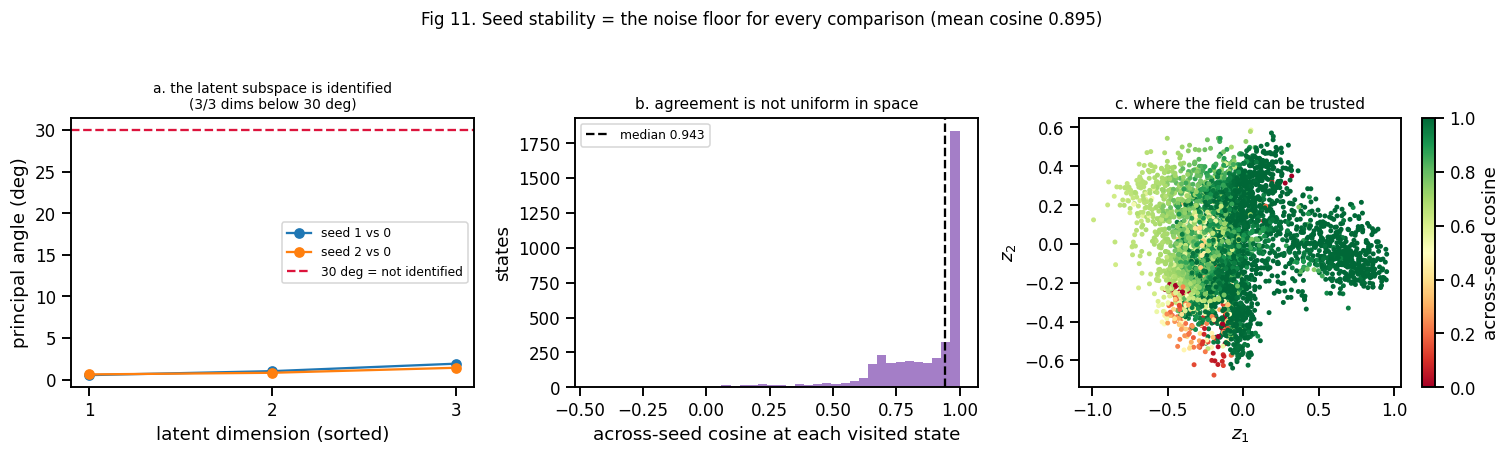

Any condition- or day-difference below must be compared against this floor,
and read only in the regions panel c shows as reliable.


In [17]:
# ---- FIGURE 11: how reproducible is the field, and WHERE? ----
agree = dy.field_agreement_map(pool_fields, REF)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
ax = axes[0]
A = np.stack([info["principal_angles_deg"] for info in align_info]) if align_info else \
    np.zeros((1, D_ANALYSIS))
for k in range(A.shape[0]):
    ax.plot(np.arange(1, A.shape[1] + 1), A[k], "o-", label=f"seed {SEEDS[k+1]} vs {SEEDS[0]}")
ax.axhline(30, color="crimson", ls="--", label="30 deg = not identified")
ax.set_xticks(np.arange(1, A.shape[1] + 1))
ax.set_xlabel("latent dimension (sorted)"); ax.set_ylabel("principal angle (deg)")
ax.legend(fontsize=8)
ax.set_title(f"a. the latent subspace is identified\n({REP['n_reproducible']}"
             f"/{D_ANALYSIS} dims below 30 deg)", fontsize=9)

ax = axes[1]
ax.hist(agree["cosine"], bins=40, color="tab:purple", alpha=0.85)
ax.axvline(float(np.median(agree["cosine"])), color="k", ls="--",
           label=f"median {np.median(agree['cosine']):.3f}")
ax.set_xlabel("across-seed cosine at each visited state"); ax.set_ylabel("states")
ax.legend(fontsize=8)
ax.set_title("b. agreement is not uniform in space", fontsize=10)

ax = axes[2]
sc = ax.scatter(REF[:, 0], REF[:, 1], c=agree["cosine"], s=5, cmap="RdYlGn",
                vmin=0, vmax=1)
plt.colorbar(sc, ax=ax, label="across-seed cosine")
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$")
ax.set_title("c. where the field can be trusted", fontsize=10)
fig.suptitle(f"Fig 11. Seed stability = the noise floor for every comparison "
             f"(mean cosine {SPREAD['mean_pairwise_cosine']:.3f})", y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

print("Any condition- or day-difference below must be compared against this floor,")
print("and read only in the regions panel c shows as reliable.")

In [18]:
# ---- attractors of the pooled ensemble field ----
ATTR, AINFO = dy.find_attractors_by_simulation(
    FIELD, LIMS, dt=PC.dt, n_steps=3000, points=Zall[::15], merge_dist=0.12,
    support_states=Zall, support_rad=RAD, max_tau_sec=3600.0)
ATTR_KEEP = [p for p in ATTR if p.in_sample_zone and p.endpoint_rel_speed < 0.1]
SLOW = dy.find_slow_points(FIELD, LIMS, points=Zall[::40], merge_dist=0.1,
                           max_starts=300, support_states=Zall, support_rad=RAD)

print(f"clusters={len(ATTR)}  slow & inside data={len(ATTR_KEEP)}  "
      f"unsettled={AINFO['frac_unsettled']:.3f}  "
      f"endpoint_rel_speed median={AINFO['endpoint_rel_speed_median']:.3f}  "
      f"radius growth={AINFO['radius_growth']:.3f}")
print("\nAttractors (ensemble field, integrating from observed states):")
for p in ATTR_KEEP[:10]:
    print(f"   {p.kind:14s} z={np.round(p.z, 3)} basin={p.basin_frac:.2f} "
          f"n_marginal={p.n_marginal} tau_slow={p.slowest_tau:.1f}s "
          f"end_rel={p.endpoint_rel_speed:.4f} nonnormality={p.non_normality:.2f}")
print("\nHow to read this:")
print("  n_marginal = 0 -> isolated point attractor;  >=1 -> continuous / line attractor")
print("  endpoint_rel_speed ~1 with unsettled ~1 -> no attractor at all (flow-through/cycle)")
print("  tau_exceeds_window -> the timescale is longer than the recording can constrain")
print(f"\nslow points found from observed states: {len(SLOW)}"
      f" (in data support: {sum(p.in_sample_zone for p in SLOW)})")
print("slow-set geometry (grid, elongation >> 1 means line-like):")
print("  ", {k: (round(v, 3) if np.isscalar(v) else np.round(v, 2))
              for k, v in dy.slow_region(FIELD, LIMS, grid_n=25).items()})

clusters=1  slow & inside data=1  unsettled=0.000  endpoint_rel_speed median=0.000  radius growth=0.967

Attractors (ensemble field, integrating from observed states):
   stable         z=[-0.348 -0.231 -0.106] basin=1.00 n_marginal=0 tau_slow=3.3s end_rel=0.0000 nonnormality=0.39

How to read this:
  n_marginal = 0 -> isolated point attractor;  >=1 -> continuous / line attractor
  endpoint_rel_speed ~1 with unsettled ~1 -> no attractor at all (flow-through/cycle)
  tau_exceeds_window -> the timescale is longer than the recording can constrain

slow points found from observed states: 29 (in data support: 29)
slow-set geometry (grid, elongation >> 1 means line-like):
   {'area_frac': 0.05, 'elongation': 2.446, 'centroid': array([-0.17, -0.21,  0.25]), 'speed_threshold': 0.102}


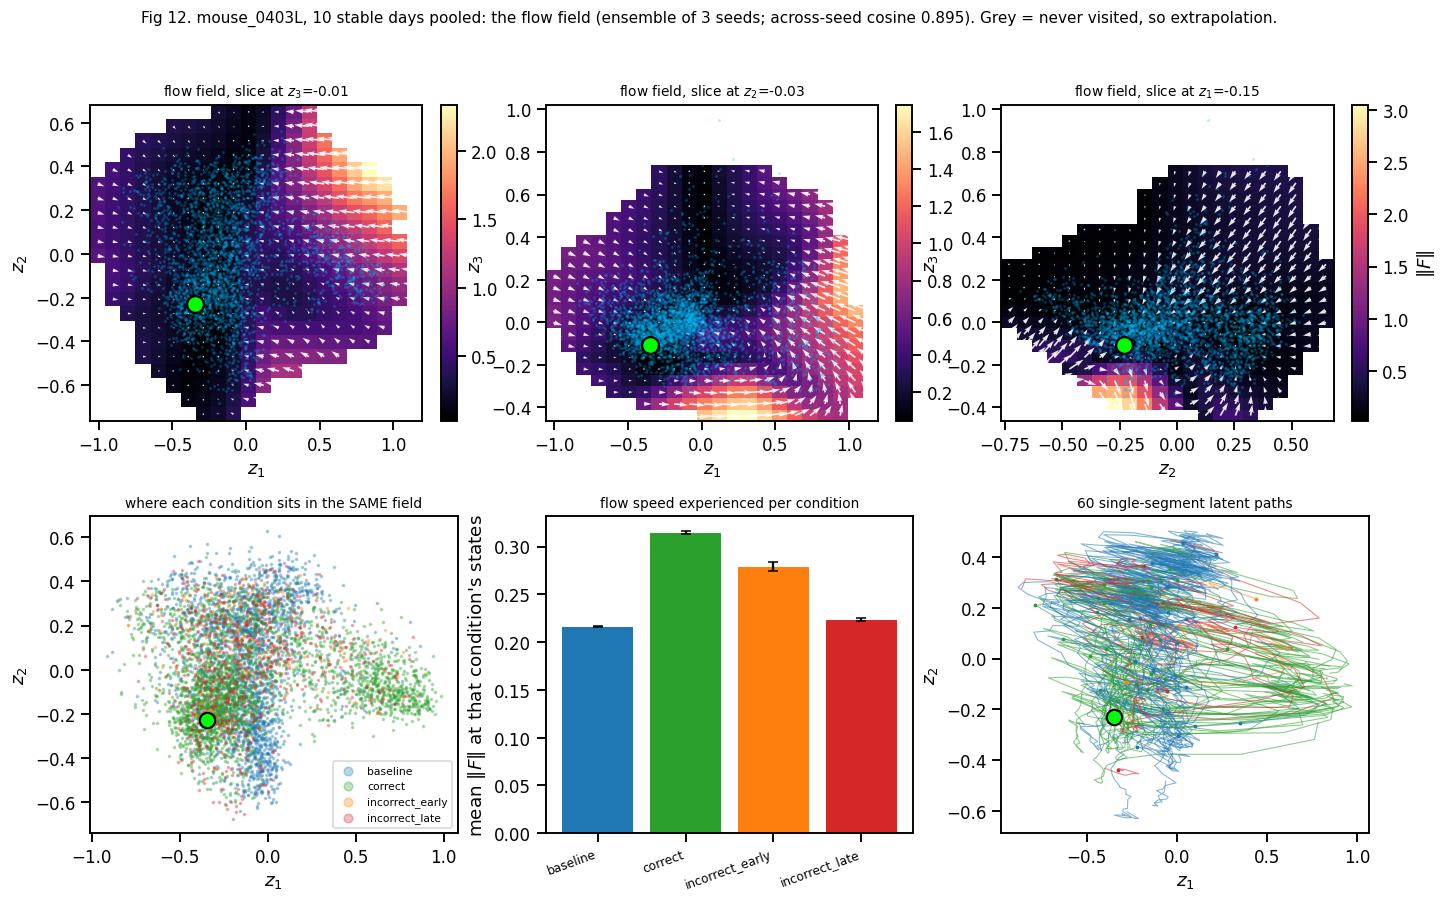

In [19]:
# ---- FIGURE 12: the flow field (2-D slices of a 3-D field) ----
PAIRS = [(0, 1), (0, 2), (1, 2)][:max(1, D_ANALYSIS * (D_ANALYSIS - 1) // 2)]
NG = 22
COND_COL = {"baseline": "tab:blue", "correct": "tab:green",
            "incorrect_early": "tab:orange", "incorrect_late": "tab:red"}

fig = plt.figure(figsize=(15, 8.6))
gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.24)
med = np.median(Zall, axis=0)
for j, (a_, b_) in enumerate(PAIRS):
    ax = fig.add_subplot(gs[0, j])
    gx, gy = np.meshgrid(np.linspace(*LIMS[a_], NG), np.linspace(*LIMS[b_], NG),
                         indexing="ij")
    P = np.tile(med, (gx.size, 1))
    P[:, a_] = gx.ravel(); P[:, b_] = gy.ravel()
    Vf = FIELD(P)
    sp = dy.speed(Vf).reshape(gx.shape)
    # mask everything the data never visits: there the field is extrapolation
    outside = dy.support_distance(P, Zall).reshape(gx.shape) > RAD
    pcm = ax.pcolormesh(gx, gy, np.ma.masked_where(outside, sp), cmap="magma",
                        shading="auto")
    ax.quiver(gx, gy, Vf[:, a_].reshape(gx.shape), Vf[:, b_].reshape(gx.shape),
              color="w", alpha=0.9, width=0.005)
    ax.scatter(Zall[::40, a_], Zall[::40, b_], s=1.2, c="deepskyblue", alpha=0.18)
    for p in ATTR_KEEP:
        ax.plot(p.z[a_], p.z[b_], "o" if p.kind == "stable" else "X", mfc="lime",
                mec="k", ms=11, mew=1.5)
    plt.colorbar(pcm, ax=ax, fraction=0.046, label="$\\|F\\|$" if j == len(PAIRS) - 1 else None)
    ax.set_xlabel(f"$z_{a_ + 1}$"); ax.set_ylabel(f"$z_{b_ + 1}$")
    others = [k for k in range(D_ANALYSIS) if k not in (a_, b_)]
    ax.set_title("flow field, slice at "
                 + ", ".join(f"$z_{k + 1}$={med[k]:.2f}" for k in others), fontsize=9)

ax = fig.add_subplot(gs[1, 0])
for c in COND:
    S = STATES[c]
    ax.scatter(S[::20, 0], S[::20, 1], s=2, c=COND_COL.get(c, "k"), alpha=0.3, label=c)
for p in ATTR_KEEP:
    ax.plot(p.z[0], p.z[1], "o" if p.kind == "stable" else "X", mfc="lime", mec="k",
            ms=10, mew=1.4)
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$"); ax.legend(fontsize=7, markerscale=4)
ax.set_title("where each condition sits in the SAME field", fontsize=9)

ax = fig.add_subplot(gs[1, 1])
nm_, mn_, se_ = [], [], []
for c in COND:
    sp_c = dy.speed(FIELD(STATES[c]))
    nm_.append(c); mn_.append(sp_c.mean()); se_.append(sp_c.std() / np.sqrt(len(sp_c)))
ax.bar(np.arange(len(nm_)), mn_, yerr=se_, capsize=3,
       color=[COND_COL.get(c, "gray") for c in nm_])
ax.set_xticks(np.arange(len(nm_)))
ax.set_xticklabels(nm_, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("mean $\\|F\\|$ at that condition's states")
ax.set_title("flow speed experienced per condition", fontsize=9)

ax = fig.add_subplot(gs[1, 2])
rng = np.random.default_rng(0)
for i in rng.choice(len(Zby), min(60, len(Zby)), replace=False):
    zz = Zby[i]
    col = COND_COL.get(pooled.meta[i]["condition"], "k")
    ax.plot(zz[:, 0], zz[:, 1], lw=0.7, color=col, alpha=0.55)
    ax.plot(zz[0, 0], zz[0, 1], ".", color=col, ms=3)
for p in ATTR_KEEP:
    ax.plot(p.z[0], p.z[1], "o" if p.kind == "stable" else "X", mfc="lime", mec="k",
            ms=10, mew=1.4)
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$")
ax.set_title("60 single-segment latent paths", fontsize=9)

fig.suptitle(f"Fig 12. {MOUSE}, {len(pool_days)} stable days pooled: the flow field "
             f"(ensemble of {len(pool_fields)} seeds; across-seed cosine "
             f"{SPREAD['mean_pairwise_cosine']:.3f}). Grey = never visited, so "
             f"extrapolation.", y=0.98, fontsize=10)
plt.show()

### 4b. The one setting that changes the answer: `c_dyn`

`c_dyn` weights the term that forces the flow field to match the dynamics the encoder infers. It
does **not** merely regularise the field — it changes *the latent itself*. At FINDR's 0.1 the
inferred trajectories on this data are essentially a random walk (increment autocorrelation ≈ 0)
and there is little deterministic motion for any field to capture. Raising it makes the path
consistent with a flow, so trajectories become smooth and much more predictable.

That is a real modelling choice with a real cost, so it is measured rather than assumed, and every
headline result later is checked across the whole range. **The existence of attractors is not
robust across it**, which is why no claim below rests on attractor existence alone.

   c_dyn=0.1: field R2=0.191/0.212 cos=0.980 inc_ac1=+0.005 attr=1 unsettled=0.00
   c_dyn=2.0: field R2=0.139/0.218 cos=0.895 inc_ac1=+0.275 attr=1 unsettled=0.00
   c_dyn=8.0: field R2=0.577/0.632 cos=0.987 inc_ac1=+0.652 attr=1 unsettled=0.94
 c_dyn    recon  r2_field  r2_ceiling  frac_of_ceiling  field_cosine  inc_autocorr  speed_cv  n_attractors  frac_unsettled
   0.1 639.9693    0.1906      0.2119           0.8998        0.9797        0.0046    1.0935             1           0.000
   2.0 643.8263    0.1388      0.2183           0.6356        0.8954        0.2751    1.0311             1           0.000
   8.0 648.4267    0.5774      0.6322           0.9133        0.9866        0.6524    1.3669             1           0.938


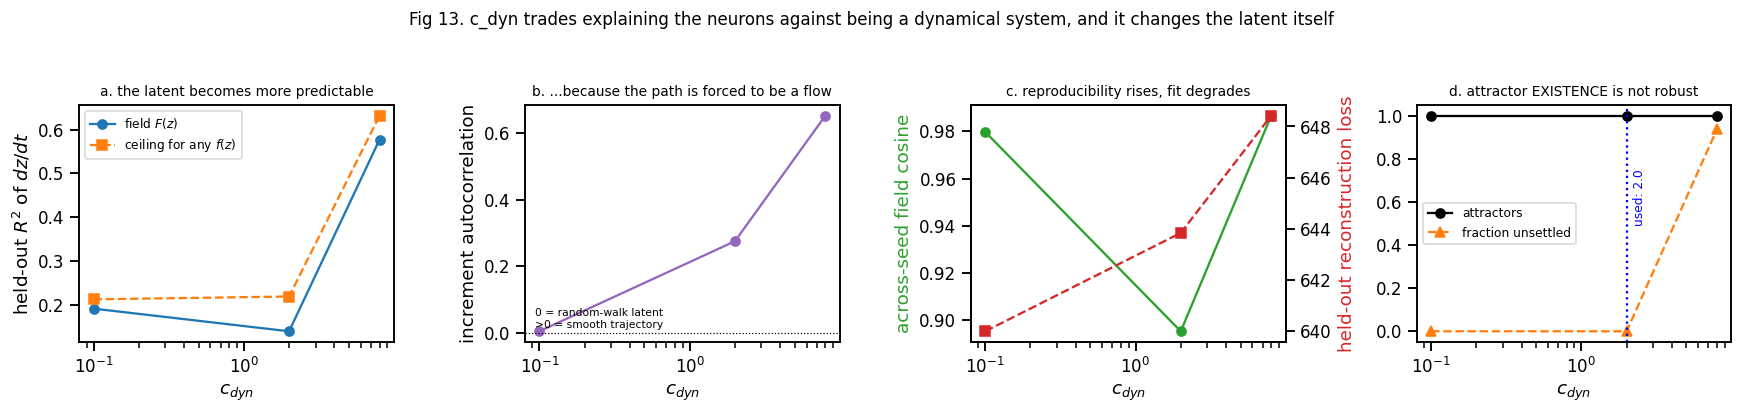


Consequence for everything below: comparisons are made at a FIXED c_dyn and
re-checked across the sweep. Claims about whether an attractor exists at all are
not supportable from this data; claims about DIFFERENCES between conditions or
blocks are, provided they exceed the across-seed floor at every c_dyn.


In [20]:
# ---- FIGURE 13: what c_dyn buys and what it costs ----
RUN_CDYN_SWEEP = True
cdyn_path = OUT / f"cdyn_sweep_{PC.tag}_p{len(pool_days)}_d{D_ANALYSIS}.csv"


def field_dz_r2(fld, Z, tr_idx, va_idx):
    '''Held-out R2 of dz/dt from the field, plus the ceiling for ANY f(z).'''
    def pairs(idx):
        X, Y = [], []
        for i in idx:
            z = Z[i]
            if z.shape[0] < 3:
                continue
            X.append(z[:-1]); Y.append(np.diff(z, axis=0) / PC.dt)
        return np.concatenate(X), np.concatenate(Y)
    Xtr, Ytr = pairs(tr_idx)
    Xte, Yte = pairs(va_idx)
    r2f = 1 - ((Yte - fld(Xte)) ** 2).sum() / ((Yte - Ytr.mean(0)) ** 2).sum()
    naive = dy.naive_flow_field([Z[i] for i in tr_idx], dt=PC.dt, kind="mlp",
                                epochs=100 if QUICK else 500)
    r2c = 1 - ((Yte - naive(Xte)) ** 2).sum() / ((Yte - Ytr.mean(0)) ** 2).sum()
    inc = float(np.mean([np.corrcoef(np.diff(z, axis=0)[:-1, k],
                                     np.diff(z, axis=0)[1:, k])[0, 1]
                         for z in Z if z.shape[0] > 6 for k in range(z.shape[1])]))
    return float(r2f), float(r2c), inc


if cdyn_path.exists() and not RUN_CDYN_SWEEP:
    cdyn_df = pd.read_csv(cdyn_path)
else:
    rows = []
    for cd in C_DYN_SWEEP:
        fs = [fit_cached(pooled, tag=f"pool{len(pool_days)}", d=D_ANALYSIS, seed=s,
                         epochs=POOL_EPOCHS, c_dyn=cd, train_idx=POOL_TR,
                         val_idx=POOL_VA) for s in SEEDS]
        FRc = frame_and_fields(fs, pooled)
        vals = [dy.evaluate(f.model, pooled, POOL_VA, seg_weights=SEG_W, c_dyn=cd)
                for f in fs]
        Zc_all = FRc["Zall"]
        refc = Zc_all[::max(1, Zc_all.shape[0] // 4000)]
        sp = dy.field_spread(FRc["fields"], points=refc)
        r2f, r2c, inc = field_dz_r2(FRc["field"], FRc["Z"], POOL_TR, POOL_VA)
        limsc = dy.limits_from_points(Zc_all, pad=0.15)
        radc = dy.support_radius(Zc_all)
        at, ai = dy.find_attractors_by_simulation(
            FRc["field"], limsc, dt=PC.dt, n_steps=3000, points=refc, merge_dist=0.12,
            support_states=Zc_all, support_rad=radc, max_tau_sec=3600.0)
        keep = [p for p in at if p.in_sample_zone and p.endpoint_rel_speed < 0.1]
        spd = dy.speed(FRc["field"](refc))
        rows.append(dict(c_dyn=cd, recon=float(np.mean([v["recon"] for v in vals])),
                         r2_field=r2f, r2_ceiling=r2c,
                         frac_of_ceiling=r2f / max(r2c, 1e-9),
                         field_cosine=sp["mean_pairwise_cosine"],
                         inc_autocorr=inc, speed_cv=float(spd.std() / spd.mean()),
                         n_attractors=len(keep), frac_unsettled=ai["frac_unsettled"]))
        print(f"   c_dyn={cd}: field R2={r2f:.3f}/{r2c:.3f} "
              f"cos={sp['mean_pairwise_cosine']:.3f} inc_ac1={inc:+.3f} "
              f"attr={len(keep)} unsettled={ai['frac_unsettled']:.2f}", flush=True)
        for f in fs:
            dy.free(f)
    cdyn_df = pd.DataFrame(rows)
    cdyn_df.to_csv(cdyn_path, index=False)
print(cdyn_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
ax = axes[0]
ax.plot(cdyn_df.c_dyn, cdyn_df.r2_field, "o-", label="field $F(z)$")
ax.plot(cdyn_df.c_dyn, cdyn_df.r2_ceiling, "s--", label="ceiling for any $f(z)$")
ax.set_xscale("log"); ax.set_xlabel("$c_{dyn}$")
ax.set_ylabel("held-out $R^2$ of $dz/dt$"); ax.legend(fontsize=8)
ax.set_title("a. the latent becomes more predictable", fontsize=9)
ax = axes[1]
ax.plot(cdyn_df.c_dyn, cdyn_df.inc_autocorr, "o-", color="tab:purple")
ax.axhline(0, color="k", lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xlabel("$c_{dyn}$")
ax.set_ylabel("increment autocorrelation")
ax.text(0.03, 0.06, "0 = random-walk latent\n>0 = smooth trajectory",
        transform=ax.transAxes, fontsize=7)
ax.set_title("b. ...because the path is forced to be a flow", fontsize=9)
ax = axes[2]
ax.plot(cdyn_df.c_dyn, cdyn_df.field_cosine, "o-", color="tab:green")
ax2 = ax.twinx()
ax2.plot(cdyn_df.c_dyn, cdyn_df.recon, "s--", color="tab:red")
ax2.set_ylabel("held-out reconstruction loss", color="tab:red")
ax.set_xscale("log"); ax.set_xlabel("$c_{dyn}$")
ax.set_ylabel("across-seed field cosine", color="tab:green")
ax.set_title("c. reproducibility rises, fit degrades", fontsize=9)
ax = axes[3]
ax.plot(cdyn_df.c_dyn, cdyn_df.n_attractors, "o-", color="k", label="attractors")
ax.plot(cdyn_df.c_dyn, cdyn_df.frac_unsettled, "^--", color="tab:orange",
        label="fraction unsettled")
ax.axvline(C_DYN, color="b", ls=":", lw=1.5)
ax.text(C_DYN * 1.1, 0.5, f"used: {C_DYN}", fontsize=8, color="b", rotation=90)
ax.set_xscale("log"); ax.set_xlabel("$c_{dyn}$"); ax.legend(fontsize=8)
ax.set_title("d. attractor EXISTENCE is not robust", fontsize=9)
fig.suptitle("Fig 13. c_dyn trades explaining the neurons against being a dynamical "
             "system, and it changes the latent itself", y=1.04, fontsize=11)
fig.tight_layout(); plt.show()

print("\nConsequence for everything below: comparisons are made at a FIXED c_dyn and")
print("re-checked across the sweep. Claims about whether an attractor exists at all are")
print("not supportable from this data; claims about DIFFERENCES between conditions or")
print("blocks are, provided they exceed the across-seed floor at every c_dyn.")

## 5. How a difference is tested

Three statistics, in increasing order of trustworthiness. The first two are shown because they were
tried and found wanting, and the reasons generalise.

**Nested held-out loss — too insensitive.** The total loss is ~652, of which reconstruction over
468 neurons is ~648 and the dynamics term only ~1.8. Changing the *field* therefore cannot move the
total much: conditioning on condition or day gained 0.04–0.06 %, mostly inside seed noise. A null
result from this statistic means nothing.

**The field's own held-out `dz` prediction — not comparable across variants.** Each variant infers
its own latent, and a model with an embedding infers a *smoother, more predictable* latent whatever
the labels mean. Measured: conditioning gained +0.018, but the **shuffled-label** model gained
**more** (+0.040). The gain is capacity, not information.

**Within-model per-partition field comparison against a label-shuffle null — this is the test.**
Fit one conditioned model, read out each partition's field, and compare fields only on the state
space the partitions actually *share*. Then refit the identical model with the labels **permuted
across segments**: that null carries the same parameters and the same flexibility, so whatever
difference it produces is the amount attributable to fitting noise. On top of that, every result is
checked at `c_dyn` ∈ {0.1, 2, 8}, and each claim also has to clear the across-seed floor.

In [21]:
# ---- helper: per-partition fields compared on shared support ----
def partition_states(segset, frame, factor):
    '''{level: (n, d) latent states} for a labelling factor.'''
    out = {}
    for i, m in enumerate(segset.meta):
        lev = m["condition"] if factor == "condition" else int(segset.labels[factor][i])
        out.setdefault(lev, []).append(frame["Z"][i])
    return {k: np.concatenate(v, axis=0) for k, v in out.items()}


def partition_field_pairs(model, frame, states, factor, code_of, *, rad=None,
                          max_pts=2500):
    '''Field distance for every pair of levels, evaluated ONLY where both go.

    Restricting to shared support is essential: outside a partition's own
    occupancy its field is extrapolation, so a comparison there measures the
    network's guesswork rather than the animal's dynamics.
    '''
    rad = dy.support_radius(frame["Zall"]) if rad is None else rad
    fl = {k: dy.field_fn(model, transform=frame["transform"],
                         labels={factor: np.array([code_of(k)])}) for k in states}
    rows = []
    for k1, k2 in itertools.combinations(sorted(states), 2):
        s1, s2 = states[k1], states[k2]
        sh = np.vstack([s1[dy.support_distance(s1, s2) <= rad],
                        s2[dy.support_distance(s2, s1) <= rad]])
        if sh.shape[0] < 50:
            continue
        sub = sh[::max(1, sh.shape[0] // max_pts)]
        dd = dy.field_distance(fl[k1], fl[k2], points=sub)
        rows.append(dict(a=k1, b=k2, cosine=dd["cosine"], nrmse=dd["nrmse"],
                         n_pts=int(sub.shape[0])))
    return pd.DataFrame(rows)


def shuffled_null(segset, factor, n_levels, *, tag, seeds=None, **fit_kw):
    '''Refit the same conditioned model with `factor`'s labels permuted.

    The label-shuffle null, and the reference every difference is judged against.
    '''
    seeds = SEEDS if seeds is None else seeds
    rows = []
    for s in seeds:
        rng = np.random.default_rng(9000 + s)
        shuf = dy.SegmentSet(Y=segset.Y, mask=segset.mask, meta=segset.meta,
                             B=segset.B, U=segset.U,
                             labels=dict(segset.labels,
                                         **{factor: rng.permutation(
                                             segset.labels[factor])}))
        res = fit_cached(shuf, tag=f"{tag}_shuf{factor}", cond_sizes={factor: n_levels},
                         seed=s, **fit_kw)
        fr = frame_and_fields([res], shuf)
        st = partition_states(shuf, fr, factor)
        code_of = (lambda k: CODE[k]) if factor == "condition" else (lambda k: k)
        rows.append(partition_field_pairs(res.model, fr, st, factor, code_of))
        dy.free(res)
    return pd.concat(rows, ignore_index=True)


def verdict(real_df, null_df, *, n_sd=2.0):
    '''Mark a pair as different only if it clears the null by n_sd.'''
    thr = float(null_df.cosine.mean() - n_sd * null_df.cosine.std())
    out = real_df.copy()
    out["differs"] = out.cosine < thr
    return out, thr


print("test helpers defined")

test helpers defined


## 6. Question 1 — the stable control phase

Two parts: does the flow field differ between **correct trials, incorrect trials and baseline**, and
does it change across **learning days**?

The trial-length confound is handled by construction: conditions are time-balanced in the loss, and
misses are split into a duration-matched head (`incorrect_early`) and the give-up tail
(`incorrect_late`), so an outcome effect cannot be a duration effect in disguise.

In [22]:
# ---- per-condition fields, at every c_dyn, with the shuffle null ----
cond_real, cond_null = {}, {}
for cd in C_DYN_SWEEP:
    fs = [fit_cached(pooled, tag=f"pool{len(pool_days)}", cond_sizes={"condition": len(COND)},
                     seed=s, epochs=POOL_EPOCHS, c_dyn=cd, train_idx=POOL_TR,
                     val_idx=POOL_VA) for s in SEEDS]
    fr = frame_and_fields(fs, pooled)
    st = partition_states(pooled, fr, "condition")
    cond_real[cd] = partition_field_pairs(fs[0].model, fr, st, "condition",
                                          lambda c: CODE[c])
    cond_null[cd] = shuffled_null(pooled, "condition", len(COND),
                                  tag=f"pool{len(pool_days)}", epochs=POOL_EPOCHS,
                                  c_dyn=cd, train_idx=POOL_TR, val_idx=POOL_VA)
    r_, thr_ = verdict(cond_real[cd], cond_null[cd])
    cond_real[cd] = r_
    print(f"c_dyn={cd}: null {cond_null[cd].cosine.mean():.4f}"
          f"+-{cond_null[cd].cosine.std():.4f}, threshold {thr_:.4f}, "
          f"{int(r_.differs.sum())}/{len(r_)} pairs differ", flush=True)
    if cd == C_DYN:
        COND_FRAME, COND_STATES, COND_FITS = fr, st, fs
    else:
        for f in fs:
            dy.free(f)

CONDS_ORD = [c for c in ["baseline", "correct", "incorrect_early", "incorrect_late"]
             if c in COND]
SHORT = {"baseline": "base", "correct": "corr", "incorrect_early": "inc-E",
         "incorrect_late": "inc-L"}
print("\nat the primary c_dyn:")
print(cond_real[C_DYN].round(4).to_string(index=False))

c_dyn=0.1: null 0.9811+-0.0211, threshold 0.9390, 4/6 pairs differ
c_dyn=2.0: null 0.9863+-0.0135, threshold 0.9593, 5/6 pairs differ
c_dyn=8.0: null 0.9905+-0.0076, threshold 0.9753, 6/6 pairs differ

at the primary c_dyn:
              a               b  cosine  nrmse  n_pts  differs
       baseline         correct  0.6754 1.1001   2513     True
       baseline incorrect_early  0.9309 0.5406   2574     True
       baseline  incorrect_late  0.9603 0.4178   2608    False
        correct incorrect_early  0.7917 0.8849   2582     True
        correct  incorrect_late  0.8084 0.7280   2506     True
incorrect_early  incorrect_late  0.9385 0.4329   2851     True


c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type numpy_array.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")
c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type pandas_dataframe.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")


locomotion-controlled: 6/6 pairs differ (threshold 0.9802)


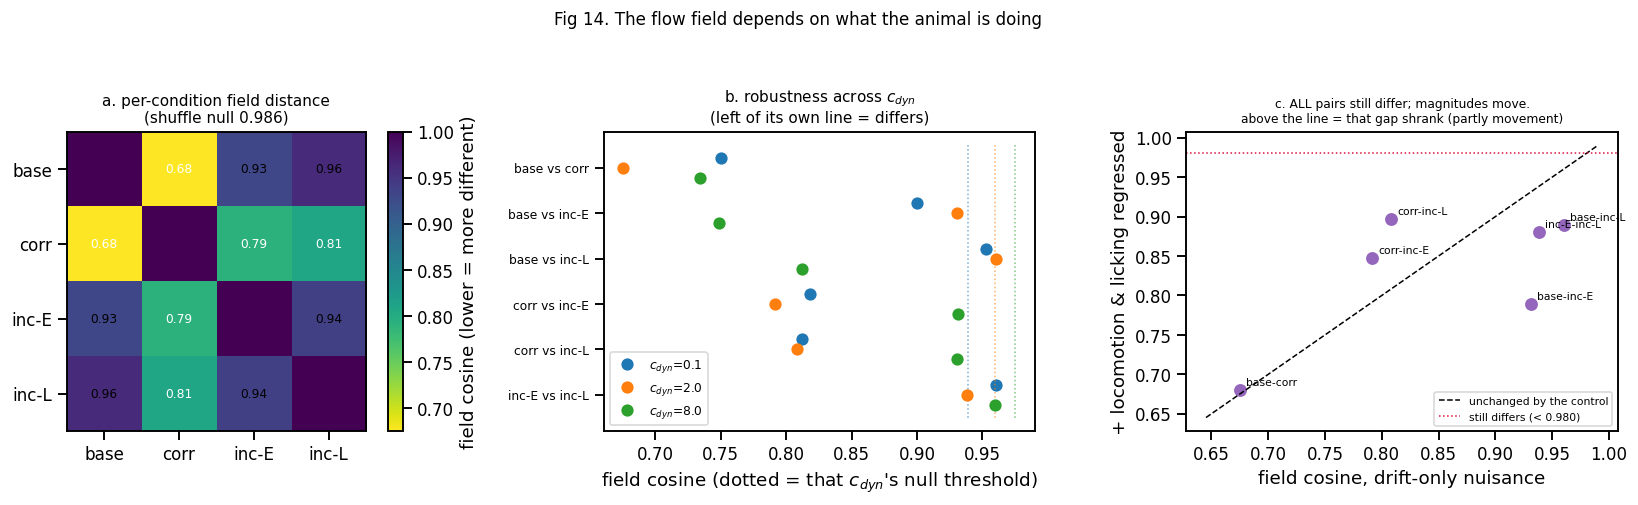


The locomotion control matters here because the mouse RUNS during baseline and
holds still during trials (treadmill z +0.71 vs -0.45, Fig 9). The headline
baseline-vs-correct difference is unchanged by regressing movement out; some of
the correct-vs-incorrect gap does shrink, so part of that one is movement-related.


In [23]:
# ---- FIGURE 14: does the field depend on condition, and is it movement? ----
RUN_LOCO_CONTROL = True
loco_real = loco_null = None
if RUN_LOCO_CONTROL:
    # rebuild the SAME pooling with locomotion + licking in the nuisance model
    _ls = []
    for k, day in enumerate(pool_days):
        ws = r["data_ws"][day].load()
        ss, _inf = load_day_segments(day, day_label=k)
        Tb_ = _inf["T_bins"]
        cov = {"tread": dy.bin_matrix(np.asarray(ws["treadmill"], float)[None, :],
                                      PC.bin_frames)[0][:Tb_],
               "lick": dy.bin_matrix(np.asarray(ws["lickometer"], float)[None, :],
                                     PC.bin_frames)[0][:Tb_]}
        nd_ = dy.n_drift_for_session(Tb_, PC.sr)
        D_, nm_, gr_ = dy.build_nuisance_design(
            Tb_, components=("drift", "covariates"), n_drift=nd_, covariates=cov)
        b_ = dy.fit_nuisance_baseline(_inf["Xb"], D_, names=nm_, groups=gr_).b
        ss.B = np.zeros_like(ss.Y)
        for i, m in enumerate(ss.meta):
            n_ = m["n_bins"]
            ss.B[i, :n_] = b_[:, m["start"]:m["end"]].T
        _ls.append(ss)
    pooled_loco = dy.concat_segment_sets(_ls)
    del _ls
    # the SAME train/val split is reused, which is only valid if the segments line up
    assert len(pooled_loco) == len(pooled), "loco pooling changed the segment set"
    assert all(a_["condition"] == b_["condition"] and a_["start"] == b_["start"]
               for a_, b_ in zip(pooled_loco.meta, pooled.meta)), \
        "loco pooling reordered segments; the shared split would be invalid"
    fs_l = [fit_cached(pooled_loco, tag=f"poolLOCO{len(pool_days)}",
                       cond_sizes={"condition": len(COND)}, seed=s, epochs=POOL_EPOCHS,
                       train_idx=POOL_TR, val_idx=POOL_VA) for s in SEEDS]
    fr_l = frame_and_fields(fs_l, pooled_loco)
    st_l = partition_states(pooled_loco, fr_l, "condition")
    loco_real = partition_field_pairs(fs_l[0].model, fr_l, st_l, "condition",
                                      lambda c: CODE[c])
    loco_null = shuffled_null(pooled_loco, "condition", len(COND),
                              tag=f"poolLOCO{len(pool_days)}", epochs=POOL_EPOCHS,
                              train_idx=POOL_TR, val_idx=POOL_VA)
    loco_real, loco_thr = verdict(loco_real, loco_null)
    print(f"locomotion-controlled: {int(loco_real.differs.sum())}/{len(loco_real)} "
          f"pairs differ (threshold {loco_thr:.4f})")
    for f in fs_l:
        dy.free(f)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
ax = axes[0]
M2 = np.full((len(CONDS_ORD), len(CONDS_ORD)), np.nan)
for _, q in cond_real[C_DYN].iterrows():
    i, j = CONDS_ORD.index(q.a), CONDS_ORD.index(q.b)
    M2[i, j] = M2[j, i] = q.cosine
np.fill_diagonal(M2, 1.0)
im = ax.imshow(M2, cmap="viridis_r", vmin=np.nanmin(M2), vmax=1.0)
for i in range(len(CONDS_ORD)):
    for j in range(len(CONDS_ORD)):
        if np.isfinite(M2[i, j]) and i != j:
            ax.text(j, i, f"{M2[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="w" if M2[i, j] < 0.85 else "k")
ax.set_xticks(range(len(CONDS_ORD))); ax.set_yticks(range(len(CONDS_ORD)))
ax.set_xticklabels([SHORT[c] for c in CONDS_ORD])
ax.set_yticklabels([SHORT[c] for c in CONDS_ORD])
plt.colorbar(im, ax=ax, label="field cosine (lower = more different)")
ax.set_title(f"a. per-condition field distance\n(shuffle null "
             f"{cond_null[C_DYN].cosine.mean():.3f})", fontsize=10)

ax = axes[1]
keys = [(q.a, q.b) for _, q in cond_real[C_DYN].iterrows()]
y = np.arange(len(keys))
for k, cd in enumerate(C_DYN_SWEEP):
    t = cond_real[cd].set_index(["a", "b"])
    vals = [float(t.loc[key, "cosine"]) if key in t.index else np.nan for key in keys]
    ax.plot(vals, y + (k - 1) * 0.22, "o", ms=7, label=f"$c_{{dyn}}$={cd}")
    thr_k = float(cond_null[cd].cosine.mean() - 2 * cond_null[cd].cosine.std())
    ax.plot([thr_k] * 2, [-0.5, len(keys) - 0.5], ls=":", lw=1, alpha=0.6, color=f"C{k}")
ax.set_yticks(y)
ax.set_yticklabels([f"{SHORT[a_]} vs {SHORT[b_]}" for a_, b_ in keys], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("field cosine (dotted = that $c_{dyn}$'s null threshold)")
ax.legend(fontsize=8)
ax.set_title("b. robustness across $c_{dyn}$\n(left of its own line = differs)",
             fontsize=10)

ax = axes[2]
if loco_real is not None:
    lm = {(q.a, q.b): q.cosine for _, q in loco_real.iterrows()}
    base_t = cond_real[C_DYN].set_index(["a", "b"])
    xs, ys, lbl = [], [], []
    for key in keys:
        v2 = lm.get(key, lm.get((key[1], key[0]), np.nan))
        if np.isfinite(v2):
            xs.append(float(base_t.loc[key, "cosine"])); ys.append(v2)
            lbl.append(f"{SHORT[key[0]]}-{SHORT[key[1]]}")
    ax.scatter(xs, ys, s=55, c="tab:purple")
    for x_, y_, t_ in zip(xs, ys, lbl):
        ax.annotate(t_, (x_, y_), fontsize=7, xytext=(4, 3), textcoords="offset points")
    lo_, hi_ = min(xs + ys) - 0.03, max(xs + ys) + 0.03
    ax.plot([lo_, hi_], [lo_, hi_], "k--", lw=1, label="unchanged by the control")
    ax.axhline(loco_thr, color="crimson", ls=":", lw=1,
               label=f"still differs (< {loco_thr:.3f})")
    ax.set_xlabel("field cosine, drift-only nuisance")
    ax.set_ylabel("+ locomotion & licking regressed")
    ax.legend(fontsize=7, loc="lower right")
    ax.set_title("c. ALL pairs still differ; magnitudes move.\nabove the line = that "
                 "gap shrank (partly movement)", fontsize=8)
fig.suptitle("Fig 14. The flow field depends on what the animal is doing", y=1.04,
             fontsize=11)
fig.tight_layout(); plt.show()

print("\nThe locomotion control matters here because the mouse RUNS during baseline and")
print("holds still during trials (treadmill z +0.71 vs -0.45, Fig 9). The headline")
print("baseline-vs-correct difference is unchanged by regressing movement out; some of")
print("the correct-vs-incorrect gap does shrink, so part of that one is movement-related.")

35/45 day pairs differ (null 0.9843, threshold 0.9623)
field distance vs day gap: Spearman rho=-0.121 p=0.4297


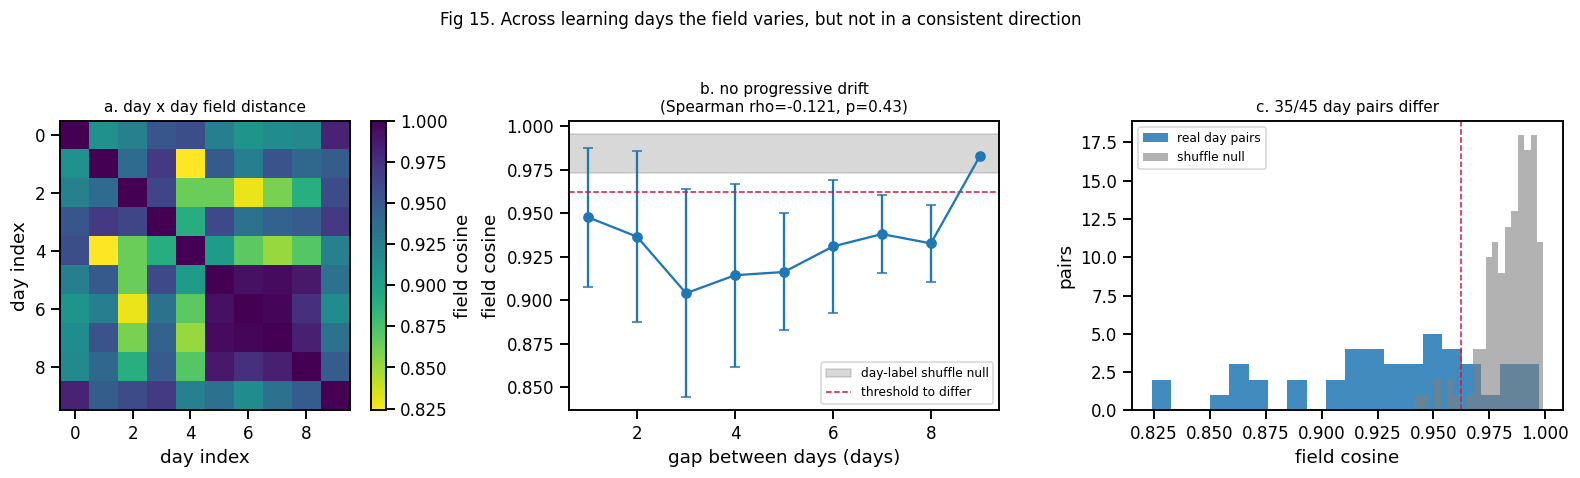


This is the answer to Q1's first half: day-to-day variation WITHOUT progressive
drift. Worth noting because many other metrics on this dataset do drift
monotonically with training day -- the flow field does not.


In [24]:
# ---- per-day fields + FIGURE 15 ----
day_fits = [fit_cached(pooled, tag=f"pool{len(pool_days)}",
                       cond_sizes={"day": len(pool_days)}, seed=s, epochs=POOL_EPOCHS,
                       train_idx=POOL_TR, val_idx=POOL_VA) for s in SEEDS]
fr_d = frame_and_fields(day_fits, pooled)
st_d = partition_states(pooled, fr_d, "day")
day_real = partition_field_pairs(day_fits[0].model, fr_d, st_d, "day", lambda k: k)
day_null = shuffled_null(pooled, "day", len(pool_days), tag=f"pool{len(pool_days)}",
                         epochs=POOL_EPOCHS, train_idx=POOL_TR, val_idx=POOL_VA)
day_real, day_thr = verdict(day_real, day_null)
day_real["gap"] = (day_real.b - day_real.a).abs()
rho_d, p_d = stats.spearmanr(day_real.gap, day_real.cosine)
print(f"{int(day_real.differs.sum())}/{len(day_real)} day pairs differ "
      f"(null {day_null.cosine.mean():.4f}, threshold {day_thr:.4f})")
print(f"field distance vs day gap: Spearman rho={rho_d:+.3f} p={p_d:.4f}")
for f in day_fits:
    dy.free(f)

nD = len(pool_days)
MD = np.full((nD, nD), np.nan)
for _, q in day_real.iterrows():
    MD[int(q.a), int(q.b)] = MD[int(q.b), int(q.a)] = q.cosine
np.fill_diagonal(MD, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
im = ax.imshow(MD, cmap="viridis_r", vmin=np.nanmin(MD), vmax=1.0)
plt.colorbar(im, ax=ax, label="field cosine")
ax.set_xlabel("day index"); ax.set_ylabel("day index")
ax.set_title("a. day x day field distance", fontsize=10)

ax = axes[1]
g = day_real.groupby("gap").cosine.agg(["mean", "std", "count"]).reset_index()
ax.errorbar(g.gap, g["mean"], yerr=g["std"], fmt="o-", capsize=3, color="tab:blue")
ax.axhspan(day_null.cosine.mean() - day_null.cosine.std(),
           day_null.cosine.mean() + day_null.cosine.std(), color="gray", alpha=0.3,
           label="day-label shuffle null")
ax.axhline(day_thr, color="crimson", ls="--", lw=1, label="threshold to differ")
ax.set_xlabel("gap between days (days)"); ax.set_ylabel("field cosine")
ax.legend(fontsize=8)
ax.set_title(f"b. no progressive drift\n(Spearman rho={rho_d:+.3f}, p={p_d:.2f})",
             fontsize=10)

ax = axes[2]
ax.hist(day_real.cosine, bins=20, color="tab:blue", alpha=0.85, label="real day pairs")
ax.hist(day_null.cosine, bins=20, color="gray", alpha=0.6, label="shuffle null")
ax.axvline(day_thr, color="crimson", ls="--", lw=1)
ax.set_xlabel("field cosine"); ax.set_ylabel("pairs"); ax.legend(fontsize=8)
ax.set_title(f"c. {int(day_real.differs.sum())}/{len(day_real)} day pairs differ",
             fontsize=10)
fig.suptitle("Fig 15. Across learning days the field varies, but not in a consistent "
             "direction", y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

print("\nThis is the answer to Q1's first half: day-to-day variation WITHOUT progressive")
print("drift. Worth noting because many other metrics on this dataset do drift")
print("monotonically with training day -- the flow field does not.")

## 7. Question 2 — the remapping days

Every remapping day is `factor 2 → 3 → 2`: intuitive-axis control, then the uncued rotation to the
new axis, then washout back to the intuitive axis. All 15 days are fitted as **one** pooled model
(27,205 s) with block, day and outcome as embeddings, because no single block-condition cell is
large enough on its own — the largest, `new | correct`, is 12,012 s and everything else is below the
~6,700 s a standalone fit needs.

**One limit to state up front.** Pooled across all 15 days, `intuitive_pre | incorrect_early` totals
**72 s in 17 segments**: before the rotation the animal essentially never fails (median hit rate
1.00 in that block). The correct/incorrect/baseline split is therefore available for the new-axis
and washout blocks but **not** for the pre-rotation block, where it is correct vs baseline only.

In [25]:
BLOCKS = ["intuitive_pre", "new", "washout"]
INTUITIVE_MIN = 10.0     # the question asks for the FIRST ~10 min of pre-rotation control


def remap_day_sets(day, day_label):
    '''One SegmentSet per block, so block and outcome stay separate factors.'''
    trials = na.get_true_bmi_trials(na.get_trials_df(r, day))
    blocks = na.segment_factor_blocks(trials)
    if len(blocks) != 3:
        return []
    out = []
    for bi, blk in enumerate(blocks):
        s_f = blk.start_frame if np.isfinite(blk.start_frame) else np.nanmin(trials.start)
        e_f = blk.end_frame
        if not np.isfinite(e_f):
            sb = trials.start[blk.first_trial:blk.last_trial + 1]
            eb = trials.end[blk.first_trial:blk.last_trial + 1]
            e_f = np.nanmax(np.concatenate([eb, sb + MISS_SEC * SR]))
        s_f, e_f = float(s_f), float(e_f + 1)
        if BLOCKS[bi] == "intuitive_pre":
            e_f = min(e_f, s_f + INTUITIVE_MIN * 60 * SR)
        ss, _ = load_day_segments(day, day_label=day_label, window=(int(s_f), int(e_f)),
                                 extra_labels={"block": bi})
        if len(ss):
            out.append(ss)
    return out


t0 = time.time()
_rs = []
for k, day in enumerate(REMAP_DAYS):
    _rs += remap_day_sets(day, k)
remap = dy.concat_segment_sets(_rs)
del _rs
print(f"POOLED remap: {remap.summary()} | {remap.mask.sum() / PC.sr:.0f} s "
      f"| {time.time() - t0:.0f}s")
for bi, bn in enumerate(BLOCKS):
    sel = remap.labels["block"] == bi
    print(f"   {bn:14s} {int(sel.sum()):5d} segs  {remap.mask[sel].sum() / PC.sr:8.0f} s")
RM_TR, RM_VA = dy.split_train_val(remap, val_frac=0.2, seed=0)

c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type pandas_dataframe.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")
c:\Users\alireza\miniconda3\envs\BCI_analysis\Lib\site-packages\richfile\util.py:295: UserWarning: Field 'versions_supported' is empty in type_lookup for type numpy_array.
  warnings.warn(f"Field 'versions_supported' is empty in type_lookup for type {metadata['type']}.")


POOLED remap: 4629 segments, 163230 valid samples, day:15 levels, condition:4 levels, block:3 levels | 27205 s | 219s
   intuitive_pre    599 segs      3636 s
   new             3450 segs     19062 s
   washout          580 segs      4507 s


In [26]:
# ---- block fields, washout hysteresis, and flow speed ----
blk_fits = [fit_cached(remap, tag=f"remap{len(REMAP_DAYS)}", cond_sizes={"block": 3},
                       seed=s, epochs=POOL_EPOCHS, train_idx=RM_TR, val_idx=RM_VA)
            for s in SEEDS]
FR_B = frame_and_fields(blk_fits, remap)
ST_B = partition_states(remap, FR_B, "block")
blk_real = partition_field_pairs(blk_fits[0].model, FR_B, ST_B, "block", lambda k: k)
blk_null = shuffled_null(remap, "block", 3, tag=f"remap{len(REMAP_DAYS)}",
                         epochs=POOL_EPOCHS, train_idx=RM_TR, val_idx=RM_VA)
blk_real, blk_thr = verdict(blk_real, blk_null)
blk_real["pair"] = [f"{BLOCKS[int(q.a)]} vs {BLOCKS[int(q.b)]}"
                    for _, q in blk_real.iterrows()]
print(f"block-shuffle null {blk_null.cosine.mean():.4f}+-{blk_null.cosine.std():.4f}, "
      f"threshold {blk_thr:.4f}")
print(blk_real[["pair", "cosine", "nrmse", "n_pts", "differs"]].round(4).to_string(index=False))

# flow speed per block: a direct field property, and more trustworthy than topology
RAD_B = dy.support_radius(FR_B["Zall"])
blk_speed = []
for bi, bn in enumerate(BLOCKS):
    fl = dy.ensemble_field([
        dy.field_fn(f.model,
                    transform=(FR_B["transform"] if f is blk_fits[0] else
                               dy.LatentTransform(
                                   FR_B["transform"].A
                                   @ np.linalg.inv(FR_B["base_transform"].A)
                                   @ dy.align_models(blk_fits[0].model, f.model)[0].A
                                   @ dy.canonical_transform(f.model).A)),
                    labels={"block": np.array([bi])}) for f in blk_fits])
    S = ST_B.get(bi)
    sp = dy.speed(fl(S))
    blk_speed.append(dict(block=bn, mean_speed=float(sp.mean()),
                          sem=float(sp.std() / np.sqrt(len(sp))), n=int(len(sp))))
blk_speed = pd.DataFrame(blk_speed)
b0 = float(blk_speed.mean_speed.iloc[0])
blk_speed["relative"] = blk_speed.mean_speed / b0
print("\nflow speed per block:")
print(blk_speed.round(4).to_string(index=False))

block-shuffle null 0.9968+-0.0031, threshold 0.9906
                    pair  cosine  nrmse  n_pts  differs
    intuitive_pre vs new  0.8926 0.3429   2546     True
intuitive_pre vs washout  0.9632 0.2164   2557     True
          new vs washout  0.9106 0.3245   2511     True

flow speed per block:
        block  mean_speed    sem      n  relative
intuitive_pre      0.8916 0.0071  21818    1.0000
          new      1.2761 0.0044 114371    1.4312
      washout      0.9104 0.0073  27041    1.0211


TypeError: bad operand type for unary -: 'method'

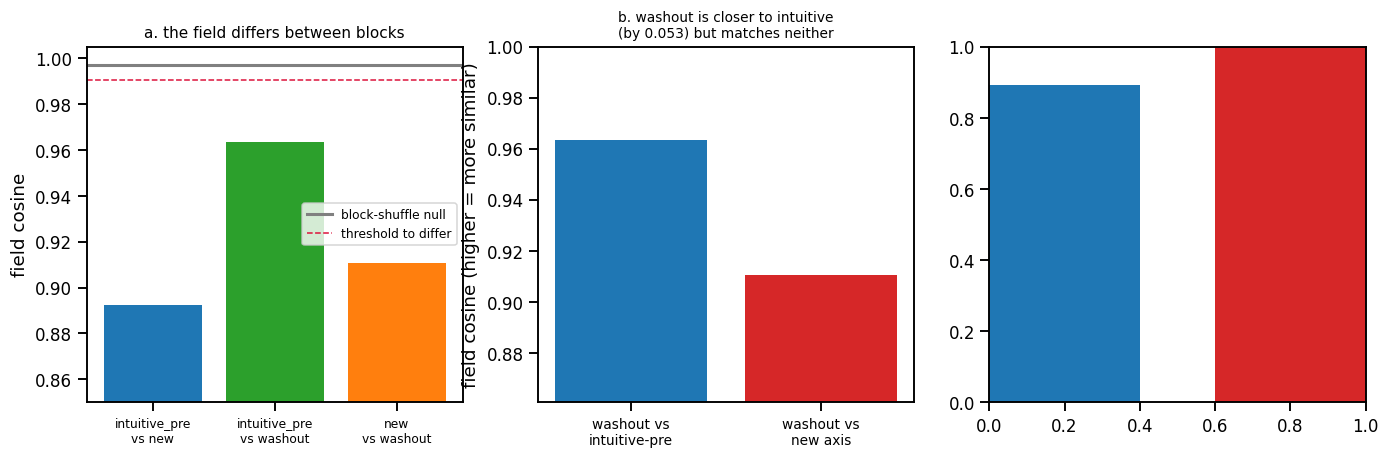

In [27]:
# ---- FIGURE 16: remapping ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
ax.bar(np.arange(len(blk_real)), blk_real.cosine,
       color=["tab:blue", "tab:green", "tab:orange"][:len(blk_real)])
ax.axhline(blk_null.cosine.mean(), color="gray", lw=2, label="block-shuffle null")
ax.axhline(blk_thr, color="crimson", ls="--", lw=1, label="threshold to differ")
ax.set_xticks(np.arange(len(blk_real)))
ax.set_xticklabels([p.replace(" vs ", "\nvs ") for p in blk_real.pair], fontsize=8)
ax.set_ylim(min(0.85, blk_real.cosine.min() - 0.02), 1.005)
ax.set_ylabel("field cosine"); ax.legend(fontsize=8)
ax.set_title("a. the field differs between blocks", fontsize=10)

ax = axes[1]
def _c(b1, b2):
    m = blk_real[((blk_real.a == b1) & (blk_real.b == b2)) |
                 ((blk_real.a == b2) & (blk_real.b == b1))]
    return float(m.cosine.iloc[0]) if len(m) else np.nan
ci, cn = _c(0, 2), _c(1, 2)
ax.bar([0, 1], [ci, cn], color=["tab:blue", "tab:red"])
ax.set_xticks([0, 1])
ax.set_xticklabels(["washout vs\nintuitive-pre", "washout vs\nnew axis"], fontsize=9)
ax.set_ylim(min(ci, cn) - 0.05, 1.0)
ax.set_ylabel("field cosine (higher = more similar)")
closer = "intuitive" if ci > cn else "new"
ax.set_title(f"b. washout is closer to {closer}\n(by {abs(ci - cn):.3f}) but matches "
             f"neither", fontsize=9)

ax = axes[2]
ax.bar(np.arange(len(blk_speed)), blk_speed.mean_speed, yerr=blk_speed.sem, capsize=4,
       color=["tab:blue", "tab:red", "tab:green"])
for i, (v, rel) in enumerate(zip(blk_speed.mean_speed, blk_speed.relative)):
    ax.text(i, v * 1.02, f"{rel:.2f}x", ha="center", fontsize=9)
ax.set_xticks(np.arange(len(blk_speed)))
ax.set_xticklabels([b.replace("_", "\n") for b in blk_speed.block], fontsize=9)
ax.set_ylabel("mean $\\|F\\|$ at that block's states")
ax.set_title("c. new-axis control has faster dynamics", fontsize=10)
fig.suptitle("Fig 16. Remapping: the field tracks the decoder axis, washout only "
             "partially returns, and new-axis control is faster", y=1.03, fontsize=11)
fig.tight_layout(); plt.show()

print("\nNote the block differences (0.90-0.96) are SMALLER than the condition")
print("differences in Fig 14 (0.68-0.96): what the animal is doing changes the dynamics")
print("more than which decoder axis it is controlling.")
print("\nAttractor COUNTS per block are deliberately not plotted -- section 4b showed")
print("counts are not robust to c_dyn. Speed and field distance are.")

## 8. What this analysis does and does not support

**Supported.**

* The flow field **depends on what the animal is doing**. Correct-trial control, failures and
  task-free baseline have measurably different dynamics — robust at every `c_dyn`, beyond both the
  across-seed floor and the label-shuffle null, and the headline baseline-vs-correct difference
  survives regressing out locomotion and licking.
* The field **differs between the remapping blocks**, and **washout only partially returns**: it is
  closer to the pre-rotation intuitive field than to the new-axis field, but matches neither.
* **New-axis control has faster dynamics** than intuitive-axis control, which agrees with the
  earlier trajectory-level finding that post-rotation control is faster.
* Across learning days the field **varies without progressive drift** (Spearman ρ ≈ −0.12, p ≈ 0.43
  against day gap) — unusual for this dataset, where many measures do drift monotonically.

**Not supported — do not read these off the figures.**

* **The number or existence of attractors.** It changes with `c_dyn`: one per condition at 0.1, two
  for correct trials at 2.0, none for correct trials at 8.0. Any two-attractor claim needs different
  evidence.
* **A 3-D autonomous field as a complete description.** It captures ~57 % of the predictable latent
  motion (field R² 0.20 of a 0.35 ceiling once history is allowed), and the residual is real
  structure, not noise — the increment autocorrelation of the residual is *positive*. More state
  dimensions or genuine input drive are missing.
* **Anything about a direction the data does not explore.** Validation showed a latent direction with
  `sd_ratio` < ~0.15 is unrecoverable by any method, and a fitted network will still place structure
  there. Hence every statistic is evaluated at observed states or inside the sample zone.

**Open, and worth doing next.**

* The autonomous field explains **baseline best and correct trials worst** (R² 0.257 vs 0.146) —
  exactly the ordering expected if the closed-loop auditory feedback drives the dynamics during
  control. That motivates the identifiable input analyses: exogenous task events as `u`, and the
  component of the tone not predictable from `z`.
* Replication in `mouse_0322R`, which has genuinely balanced outcomes (hit rates 0.07–0.85) rather
  than 0403L's ceiling performance, for the correct-vs-incorrect contrast.